# Bird species classification with few labels

Few-shot classification, labeling with the classifier's help, then a fine-tuned network, on NABirds.

- **Author:** Hussein Loubani
- **Dataset:** NABirds (Cornell Lab of Ornithology), the copy on Activeloop the brief links to: 48,561 photographs of North American birds in 555 visual categories
- **Target:** the category of the bird in each photograph. A category is a species, and for species whose males, females or juveniles look different, one plumage of that species
- **Task:** 555-class image classification, first with at most five labels per class and a labeling loop, then with a pretrained network trained on the fully labeled training set
- **Primary metric:** top-1 accuracy on the combined test set, the brief's metric and its 70% target; top-5 accuracy, macro F1 and species-level accuracy are secondary

### Table of contents

1. [Imports and setup](#1.-Imports-and-setup)
2. [Problem definition](#2.-Problem-definition)
3. [Data download and first audit](#3.-Data-download-and-first-audit)
4. [Data cleaning](#4.-Data-cleaning)
5. [Partitions](#5.-Partitions)
6. [Exploratory data analysis](#6.-Exploratory-data-analysis)
7. [Embeddings and the few-shot classifier](#7.-Embeddings-and-the-few-shot-classifier)
8. [Labeling with the classifier's help](#8.-Labeling-with-the-classifier's-help)
9. [The uptrained classifier](#9.-The-uptrained-classifier)
10. [Final evaluation on the combined test set](#10.-Final-evaluation-on-the-combined-test-set)
11. [Explaining the fine-tuned model with LIME](#11.-Explaining-the-fine-tuned-model-with-LIME)
12. [Conclusion, limitations and recommendations](#12.-Conclusion,-limitations-and-recommendations)

## 1. Imports and setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from bird_species import config
from bird_species.dataset import (
    assign_partitions,
    audit_images,
    audit_summary,
    box_in_crop,
    box_kept_by_crop,
    clip_boxes,
    download_nabirds,
    draw_shots,
    load_classes,
    partition_summary,
    pixel_moments,
    variant_examples,
    write_processed,
)
from bird_species.duplicates import (
    band_kinds,
    band_profile,
    duplicate_groups,
    hash_array,
    hash_pairs,
    resolve_duplicates,
    sample_band,
    similar_pairs,
)
from bird_species.embeddings import (
    Backbone,
    cached_embeddings,
    clip_text_embeddings,
    eval_transform,
    normalization,
)
from bird_species.episodic import project, prototype_accuracy, split_species, train_projection
from bird_species.explain import explain_many, mask_overlap, model_input, probability_function
from bird_species.fewshot import (
    PrototypeClassifier,
    careless_labeler,
    classification_metrics,
    compare_backbones,
    compare_rankings,
    first_round_reaching,
    labeler_robustness,
    labeling_loop,
    labeling_with_answers,
    lookalike_matrix,
    oracle,
    prototype_neighbors,
    shot_curve,
    verification_cases,
    zero_shot_scores,
)
from bird_species.modeling.evaluate import (
    accuracy_by_closeness,
    accuracy_by_size,
    apply_temperature,
    best_and_worst,
    cached_predictions,
    calibration_error,
    class_mix_accuracy,
    confused_pairs,
    error_kinds,
    fit_temperature,
    image_predictor,
    nearest_reference_similarity,
    negative_log_likelihood,
    per_class_accuracy,
    reliability_table,
    reweighted_accuracy,
    score_models,
    time_per_image,
)
from bird_species.modeling.train import (
    fine_tune,
    fit_head,
    head_scores,
    read_history,
    trainable_share,
    tune_head,
)
from bird_species.plots import (
    apply_style,
    image_grid,
    lime_grid,
    pair_grid,
    photo_panels,
    plot_accuracy_by_size,
    plot_bird_size,
    plot_class_counts,
    plot_duplicate_profile,
    plot_geometry,
    plot_head_search,
    plot_labeler_robustness,
    plot_labeling_history,
    plot_learning_curves,
    plot_lime_overlap,
    plot_model_comparison,
    plot_moments,
    plot_per_class,
    plot_prototype_neighbors,
    plot_query_strategies,
    plot_reliability,
    plot_runs,
    plot_shot_curves,
    plot_variants,
    save_figure,
    verification_grid,
)
from bird_species.statistics import paired_comparison

apply_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

All logic lives in the `bird_species` package under `src/`, installed in editable mode, and every constant is in `config.py`. The notebook calls functions and interprets what they return. Expensive results (image features, trained weights, test predictions, LIME explanations) are cached on disk the first time they are computed, each with a fingerprint of everything that produced it: the photographs and labels, the starting weights, every setting and the seed. A rerun of this notebook repeats every analysis in minutes instead of hours, and any change to those inputs recomputes the result instead of reloading a stale one under the same name; the learning curves of the cached training runs are read back from their logs.

## 2. Problem definition

**The situation the brief sets up:** a team wants a bird classifier but has photographs without labels, and labeling 555 fine-grained categories is slow expert work. The brief asks for the cheapest path first: classify with a handful of labeled photographs per class (one-shot or few-shot), let that classifier propose labels for the unlabeled photographs, have a person confirm the confident proposals, and repeat until the classifier reaches 70% accuracy. Only then is a conventional classifier trained on the fully labeled training set, and the two approaches are compared.

**Why this is hard:** NABirds splits many species by plumage. "Red-winged Blackbird (Male)" and "Red-winged Blackbird (Female/juvenile)" are different classes, and so are several look-alike sparrows, gulls and hawks. Telling these apart depends on small field marks, which is the definition of fine-grained classification.

**ML formulation:** single-label, 555-class image classification. Every model below maps a photograph to a score per class and predicts the highest.

**Metric:** top-1 accuracy, because the brief states its target in accuracy and because every photograph counts equally for someone sorting a photo collection. The test set is close to balanced (9 to 60 photographs per class, median 45), so accuracy is not dominated by a few large classes; macro F1 is reported beside it to show the classes that accuracy averages away. Top-5 accuracy measures whether the right answer is at least on a short list a person could check, and species-level accuracy forgives a male/female mix-up, which separates "wrong plumage" from "wrong bird".

## 3. Data download and first audit

In [2]:
metadata = download_nabirds()
classes = load_classes()
counts = metadata.groupby("split").agg(
    images=("filename", "size"), classes=("class_index", "nunique")
)
display(counts.assign(official_images=pd.Series(config.OFFICIAL_COUNTS)))
print(f"{len(classes)} leaf classes covering {classes['species'].nunique()} species")

,images,classes,official_images
split,,,
test,24633,555,24633
train,23928,555,23929


555 leaf classes covering 404 species


**One training photograph is missing and the test split is complete:** the Activeloop copy holds 23,928 training photographs against the 23,929 of the official release, and all 24,633 test photographs. The copy keeps no original file names, so there is no way to say which photograph is missing, and one in 23,929 cannot move any result. Every one of the 555 classes appears in both splits, and the classes carry 404 distinct species names, which section 6 takes apart.

In [3]:
audit = audit_images(metadata)
display(audit_summary(audit))
display(audit.loc[audit["too_small"], ["filename", "split", "width", "height"]])

,split,images,fails_decode,not_rgb,shape_mismatch,too_small,box_outside,identical_bytes
0,test,24633,0,0,0,1,104,0
1,train,23928,0,0,0,2,79,0


,filename,split,width,height
17377,train/17377.jpg,train,98,100
20773,train/20773.jpg,train,90,100
38243,test/14315.jpg,test,157,98


**Every file decodes, and the photographs themselves are clean:** no file fails a full decode, all of them are RGB at the size Activeloop records, and no two files are byte-identical. Three photographs are under 100 pixels on their short side, two in training (98x100 and 90x100) and one in test (157x98). They are genuine bird photographs that happen to be small, an outlier rather than an error, so they stay. What the audit does flag is 183 bounding boxes that run past the photograph's edge, 79 in training and 104 in test.

## 4. Data cleaning

### Bounding boxes that run past the photograph

183 boxes run past the frame, the worst by 221 px


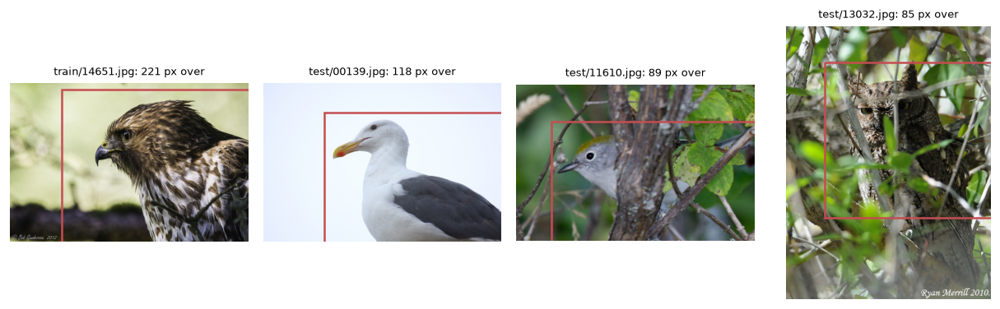

In [4]:
outside = audit[~audit["box_inside"]].nlargest(config.BOX_EXAMPLES, "box_overshoot")
overshooting = int((~audit["box_inside"]).sum())
print(
    f"{overshooting} boxes run past the frame, the worst by {audit['box_overshoot'].max():.0f} px"
)
titles = (
    outside["filename"]
    + ": "
    + outside["box_overshoot"].round().astype(int).astype(str)
    + " px over"
)
fig = image_grid(photo_panels(outside, titles.tolist()), columns=config.GRID_COLUMNS)
save_figure(fig, "box_overshoot", "cleaning")
plt.show()
data = clip_boxes(audit)

**The overshooting boxes are misplaced annotations on frame-filling birds:** in the four worst cases the bird fills the frame, and the box starts partway into the bird and runs past the right and bottom edges, by up to 221 pixels, as if it had been drawn on a differently cropped copy of the photograph. The birds really do reach the edge, so the boxes are clipped to the frame and the photographs kept; that touches 183 of 48,561 boxes. No model ever sees a box. They are used only to measure how much of the frame the bird fills (section 6) and to grade LIME's explanations (section 11), and both read a box as "roughly where the bird is".

### Duplicates: first attempt with a perceptual hash

No two files share a SHA-256 (the `identical_bytes` column above), so no photograph was saved twice byte for byte. The subtler copies are a photograph saved again at another size or crop, and burst frames: two exposures of one bird in one scene a fraction of a second apart. A copy that sits in both the training and the test data lets the test score reward memory instead of recognition.

The standard first tool is a perceptual hash, which reduces a 32x32 grayscale thumbnail to 64 bits, one per low-frequency DCT coefficient, marking whether it lies above the median of the 64, so two copies of one photograph should differ in few bits. The table checks that claim with the training labels only (test labels are blanked out, so they cannot shape a cleaning threshold): two copies of one photograph cannot carry different labels, so the share of close pairs with different labels is a floor on how often the hash matches different birds.

In [5]:
train_labels = audit["class_index"].where(audit["split"] == "train")
display(band_profile(hash_pairs(hash_array(audit["phash"])), "distance", None, train_labels))

,band,pairs,labeled_pairs,cross_label_pairs,cross_label_%
0,0,209,88,22,25.0
1,2,412,165,154,93.3
2,4,1387,400,389,97.2
3,6,4252,1067,1046,98.0
4,8,12817,3228,3177,98.4


**The perceptual hash cannot tell a copy from a look-alike here, so it is rejected as the matcher:** at Hamming distance 0, where two hashes are identical, 22 of the 88 checkable training pairs carry different labels (25%), and at distance 2 the share is already 93.3%. A 64-bit hash of a 32x32 thumbnail records little more than "a dark shape in the middle of a smooth background", which describes thousands of different birds against sky or water. Only even distances occur because each hash marks which of its 64 coefficients lie above their median, so every hash has exactly 32 ones and two of them always differ in an even number of bits.

### Duplicates: matching on content with DINOv2 embeddings

A DINOv2 embedding (section 7 explains the model) describes what is in the photograph rather than how light and dark are laid out, and it barely moves under a resize, a re-crop or a change of JPEG quality. Every photograph is compared with every other by cosine similarity, block by block.

In [6]:
dino = cached_embeddings(config.FEWSHOT_BACKBONE, audit["filename"])
close, nearest = similar_pairs(dino)
profile = band_profile(close, "similarity", config.SIMILARITY_BANDS, train_labels)
display(
    pd.concat(
        [profile, band_kinds(close, config.SIMILARITY_BANDS, audit["split"].to_numpy())], axis=1
    )
)

,band,pairs,labeled_pairs,cross_label_pairs,cross_label_%,test-test,train-test,train-train
0,"[0.8, 0.85)",453459,109165,55996,51.3,118362,225932,109165
1,"[0.85, 0.9)",165307,40074,15388,38.4,44184,81049,40074
2,"[0.9, 0.92)",17394,4360,993,22.8,4755,8279,4360
3,"[0.92, 0.94)",5639,1450,200,13.8,1643,2546,1450
4,"[0.94, 0.95)",779,225,18,8.0,254,300,225
5,"[0.95, 0.96)",315,119,13,10.9,110,86,119
6,"[0.96, 0.97)",104,41,1,2.4,45,18,41
7,"[0.97, 0.98)",42,17,0,0.0,22,3,17
8,"[0.98, 0.99)",11,6,0,0.0,5,0,6
9,"[0.99, 1.0)",198,77,0,0.0,108,13,77


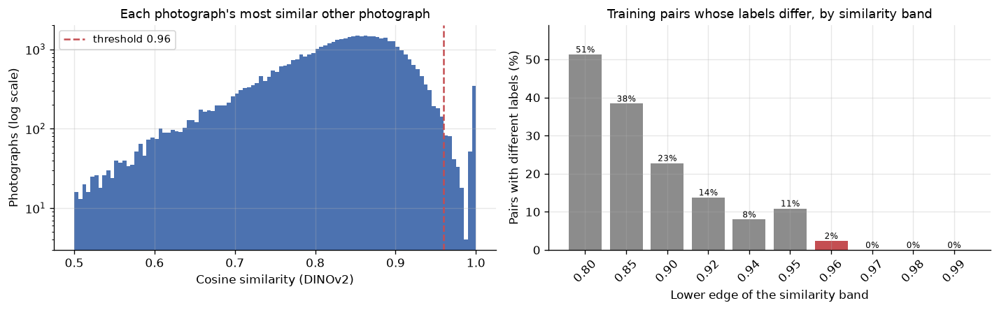

In [7]:
fig = plot_duplicate_profile(nearest, profile, config.DUPLICATE_SIMILARITY)
save_figure(fig, "duplicate_profile", "cleaning")
plt.show()

**Above 0.96 the matcher finds copies; below it, mostly look-alikes:** each photograph's nearest-neighbor similarity has a separate spike between 0.99 and 1.0, photographs whose nearest neighbor is a copy of themselves, and a thin tail from 0.96 to 0.99 before the bulk of ordinary neighbors. The training labels draw the line in the same place: no training pair in the three bands from 0.97 up disagrees (17, 6 and 77 pairs), 1 of the 41 between 0.96 and 0.97 does, and the share jumps to 10.9% between 0.95 and 0.96 and keeps climbing below. **The threshold is 0.96:** it is read off the label-free histogram and checked with training labels only, so no test label decided which photographs stay. Above it, the train-test column counts 18, 3, 0 and 13 pairs that join a training photograph to a test photograph, the leak this step exists to close.

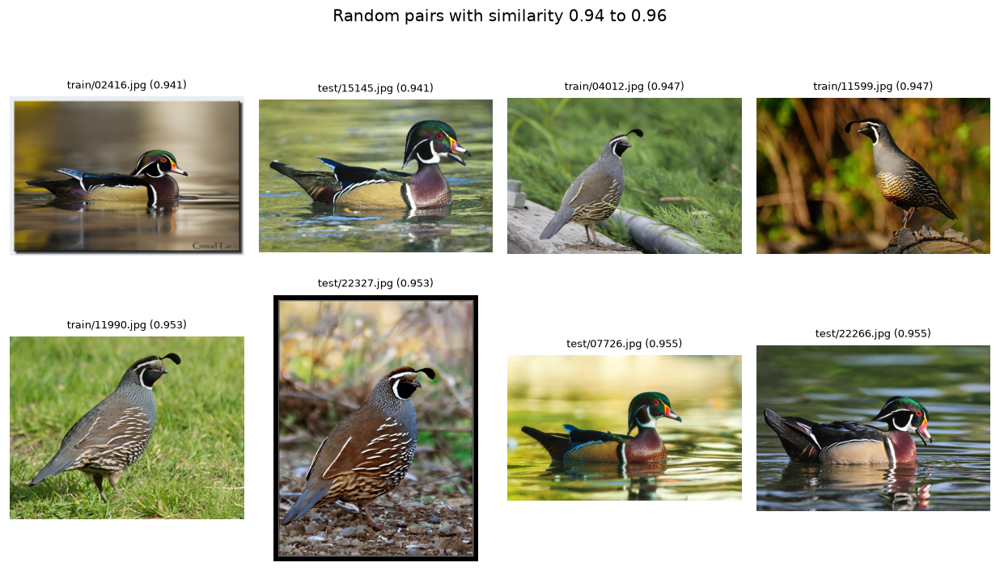

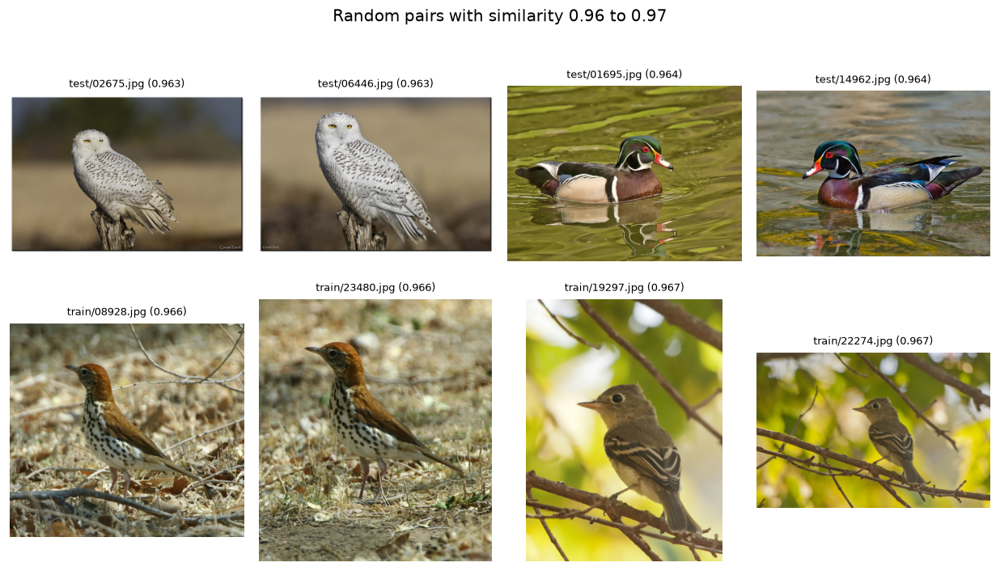

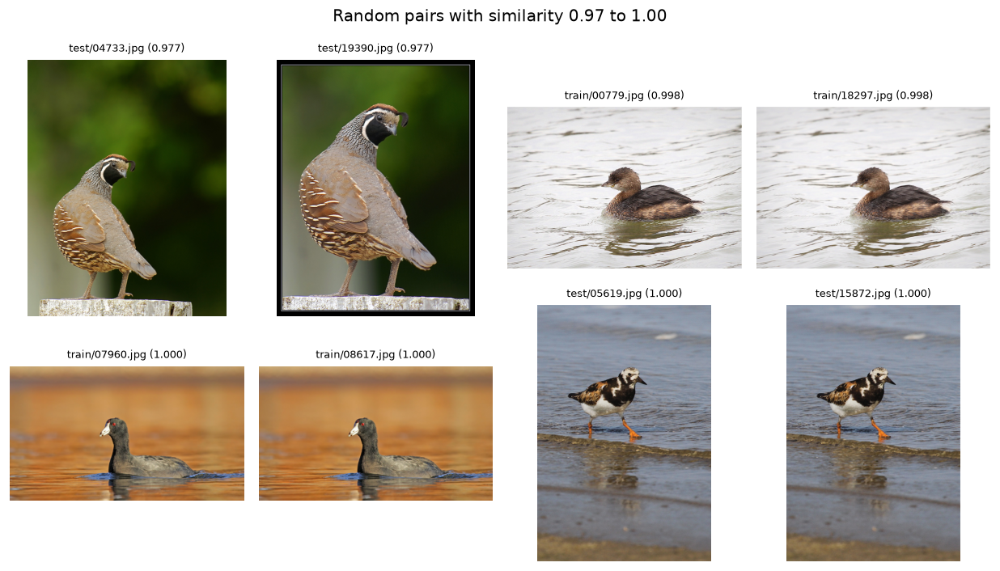

In [8]:
for low, high in config.DUPLICATE_REVIEW_BANDS:
    pairs = sample_band(close, low, high, config.DUPLICATE_EXAMPLES, config.RANDOM_SEED)
    fig = pair_grid(pairs, audit, f"Random pairs with similarity {low:.2f} to {min(high, 1.0):.2f}")
    save_figure(fig, f"pairs_from_{low:.2f}", "cleaning")
    plt.show()

**The photographs confirm where the line sits:** between 0.94 and 0.96 the sampled pairs are different birds of one species in similar poses, two male Wood Ducks and two California Quail each, which must stay separate. Between 0.96 and 0.97, three of the four pairs show one bird in one scene photographed twice or cropped differently (a Snowy Owl, a Wood Thrush, a small flycatcher) and one shows two different male Wood Ducks, a plumage so uniform between individuals that the embedding cannot separate them. Above 0.97 every pair is the same photograph, once with a frame added. A false merge costs one photograph while a missed copy leaks into the test score, so the threshold sits at the bottom of the band where copies dominate.

In [9]:
groups = duplicate_groups(len(audit), close)
resolved = resolve_duplicates(data, groups)
display(resolved.groupby(["split", "drop_reason"]).size().unstack(fill_value=0))
clean = resolved[resolved["drop_reason"] == ""]
size_counts = np.bincount(np.bincount(groups))
group_sizes = {size: int(n) for size, n in enumerate(size_counts) if size > 1 and n}
print(f"kept {len(clean):,} of {len(resolved):,}; groups of 2+ photographs by size: {group_sizes}")

drop_reason,,copy of a test image,label conflict,repeat within split
split,,,,
test,24455,0,0,178
train,23761,28,10,129


kept 48,216 of 48,561; groups of 2+ photographs by size: {2: 292, 3: 13, 4: 3, 5: 1, 6: 1, 9: 1}


**345 photographs leave the data, from 48,561 down to 48,216:** 28 training photographs that copy a test photograph (removed from training, so the test set keeps every distinct photograph), 10 training photographs in groups whose labels disagree, and 129 training and 178 test photographs that repeat another photograph of their own split. The duplicate groups stay small, 292 pairs, 13 triples and a handful of larger groups of up to 9 photographs, so the similarity graph does not chain unrelated birds together.

## 5. Partitions

The brief fixes two of the three partitions. The test set is the original validation and test data combined; on Activeloop that is the single "val" split, which is NABirds' official test split, so the combined test set is that split after cleaning. Nothing in sections 6 to 9 reads a test label, except the stopping rule the brief itself places on the test set in section 8.

The training split becomes the pool the labeling loop draws from. Before anything is drawn, 10% of it is set aside as a validation set for every choice made along the way (backbone, ranking rule, head hyperparameters, learning rate, number of epochs), stratified by class and never taking a class below five photographs, so a five-shot start stays possible everywhere.

In [10]:
parts = assign_partitions(clean)
display(partition_summary(parts))
train, val, test = (parts[parts["partition"] == name] for name in ("train", "validation", "test"))
labels = audit["class_index"].to_numpy()
species = classes["species"].to_numpy()

,partition,images,classes,per_class_min,per_class_median,per_class_max
0,train,21364,555,4,40.0,54
1,validation,2397,553,1,4.0,6
2,test,24455,555,9,45.0,60


**The partitions are sealed before any model runs:** 21,364 training photographs (4 to 54 per class, median 40), 2,397 validation photographs (1 to 6 per class over 553 classes, because the two classes with five or fewer photographs cannot spare one and still allow a five-shot start), and the 24,455-photograph test set (9 to 60 per class, median 45). Every class keeps at least 4 training photographs, so the labeling loop can start anywhere with one.

## 6. Exploratory data analysis

### Classes and their sizes

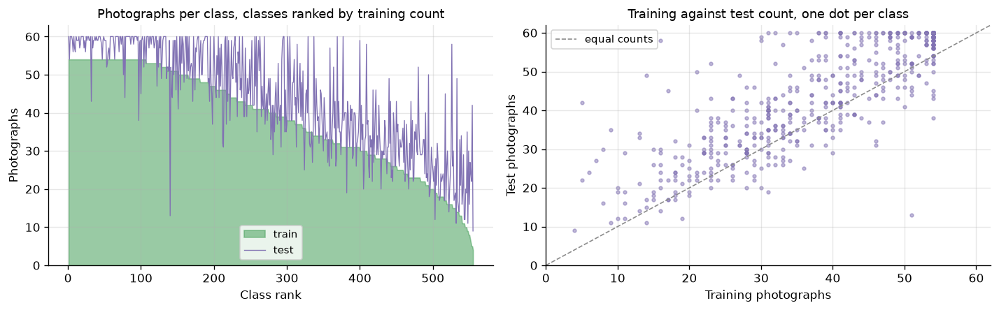

training photographs per class: min 4, median 40, max 54; correlation between training and test counts 0.84


In [11]:
train_counts = np.bincount(train["class_index"], minlength=len(classes))
test_counts = np.bincount(test["class_index"], minlength=len(classes))
fig = plot_class_counts(train_counts, test_counts)
save_figure(fig, "class_counts", "eda")
plt.show()
correlation = np.corrcoef(train_counts, test_counts)[0, 1]
print(
    f"training photographs per class: min {train_counts.min()}, "
    f"median {np.median(train_counts):.0f}, max {train_counts.max()}; "
    f"correlation between training and test counts {correlation:.2f}"
)

**The classes are imbalanced but not wildly, and the two splits mirror each other:** training classes hold 4 to 54 photographs (median 40), and a class's training and test counts correlate at 0.84, so the test set over- and under-represents the same classes the training set does. The ceiling of 54 is the official 60 minus the validation share. Test accuracy therefore weights classes much as training does, and macro F1 is reported beside it so the smallest classes still count.

### One species, several classes

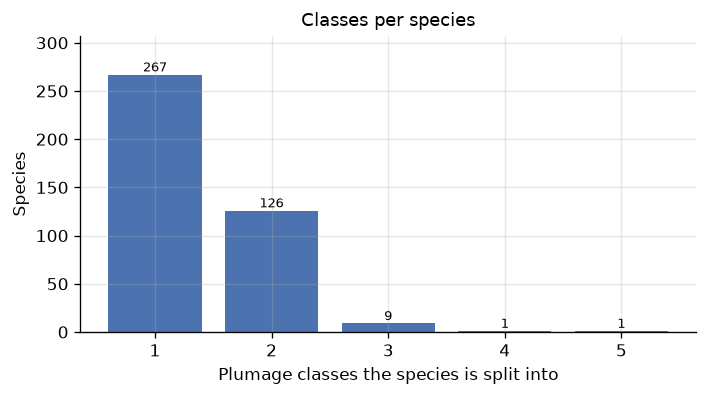

404 species; 137 are split into plumage classes, which make up 288 of the 555 classes


In [12]:
variants = classes.groupby("species").size()
fig = plot_variants(variants)
save_figure(fig, "variants", "eda")
plt.show()
multi_class_species, their_classes = (variants > 1).sum(), variants[variants > 1].sum()
print(
    f"{len(variants)} species; {multi_class_species} are split into plumage classes, "
    f"which make up {their_classes} of the {len(classes)} classes"
)

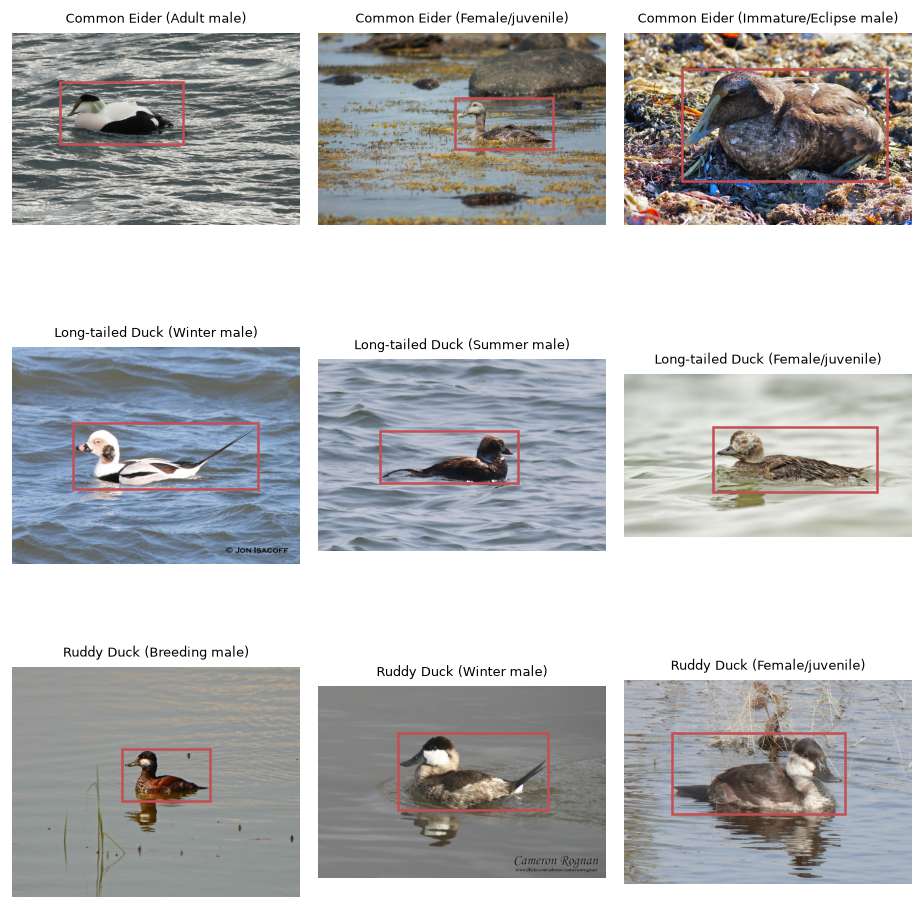

In [13]:
examples = variant_examples(train, classes, config.VARIANT_EXAMPLES, config.VARIANTS_PER_SPECIES)
fig = image_grid(
    photo_panels(examples, examples["class_name"].tolist()), columns=config.VARIANTS_PER_SPECIES
)
save_figure(fig, "variant_examples", "eda")
plt.show()

**Over half the classes exist because NABirds splits species by plumage:** 137 of the 404 species are split into two to five classes, and those species account for 288 of the 555 classes. The examples show what that asks of a model. The Common Eider's adult male is black and white while its females and young are brown, the Long-tailed Duck's winter and summer males share one shape and trade their dark and white patches, and the Ruddy Duck's breeding male is chestnut where its winter male is gray. A classifier has to learn that very different birds belong to one species and still keep apart the look-alike plumages of different species.

### Photograph size and shape

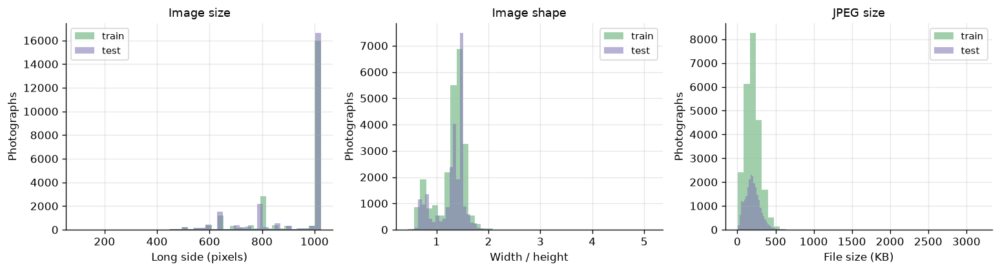

,long_side,aspect,file_bytes,box_fraction
partition,,,,
test,1024.0,1.356,197813.0,0.281
train,1024.0,1.344,195657.5,0.284
validation,1024.0,1.340,195748.0,0.284


In [14]:
fig = plot_geometry(parts)
save_figure(fig, "geometry", "eda")
plt.show()
geometry = parts.assign(
    long_side=parts[["width", "height"]].max(axis=1), aspect=parts["width"] / parts["height"]
)
display(
    geometry.groupby("partition")[["long_side", "aspect", "file_bytes", "box_fraction"]]
    .median()
    .round(3)
)

**The photographs are uniform in size and shape, and training and test match:** the median long side is 1,024 pixels in every partition (the histogram's spike shows most photographs were stored with exactly that long side), most are wider than tall at about 3:2 (median width-to-height ratio 1.34 to 1.36), and the median JPEG is about 196 kB. Nothing here differs between training and test, so there is no shift in size or compression for a model to trip over.

### How big the bird is and where it sits

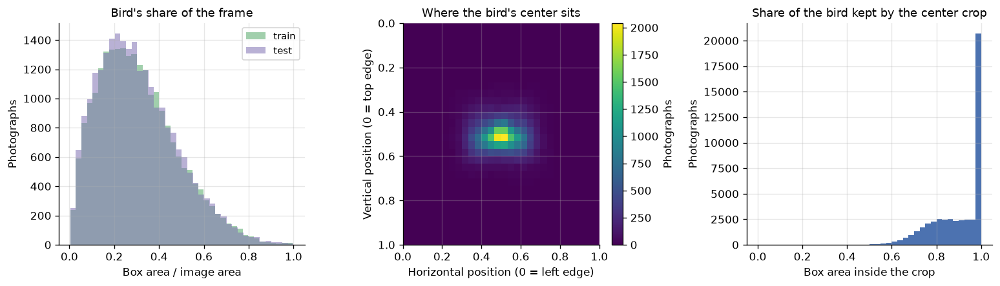

the center crop keeps at least 90% of the bird's box in 58.1% of photographs, all of it in 38.0%, under 50% in 0.3%
birds filling under 10% of the frame: 10.6% of photographs


In [15]:
kept = box_kept_by_crop(parts)
fig = plot_bird_size(parts, kept)
save_figure(fig, "bird_size", "eda")
plt.show()
high, low = config.CROP_KEEP_LEVELS
print(
    f"the center crop keeps at least {high:.0%} of the bird's box in {np.mean(kept >= high):.1%} "
    f"of photographs, all of it in {np.mean(np.isclose(kept, 1.0)):.1%}, "
    f"under {low:.0%} in {np.mean(kept < low):.1%}"
)
small_share = np.mean(parts["box_fraction"] < config.SMALL_BIRD_SHARE)
print(
    f"birds filling under {config.SMALL_BIRD_SHARE:.0%} of the frame: "
    f"{small_share:.1%} of photographs"
)

**The bird usually sits in the middle and fills about a quarter of the frame:** the median box covers 28% of the photograph in every partition, and box centers cluster tightly around the middle of the frame. That makes the center crop every model uses safe: it keeps at least 90% of the bird's box in 58.1% of photographs, all of it in 38.0%, and less than half in 0.3%. The real cost of a fixed 224-pixel input is resolution, not framing. In 10.6% of photographs the bird fills under a tenth of the frame, which after resizing leaves it roughly 100 pixels across, with few pixels for the field marks that separate the closest classes; section 10 checks how accuracy changes with bird size.

### The average photograph

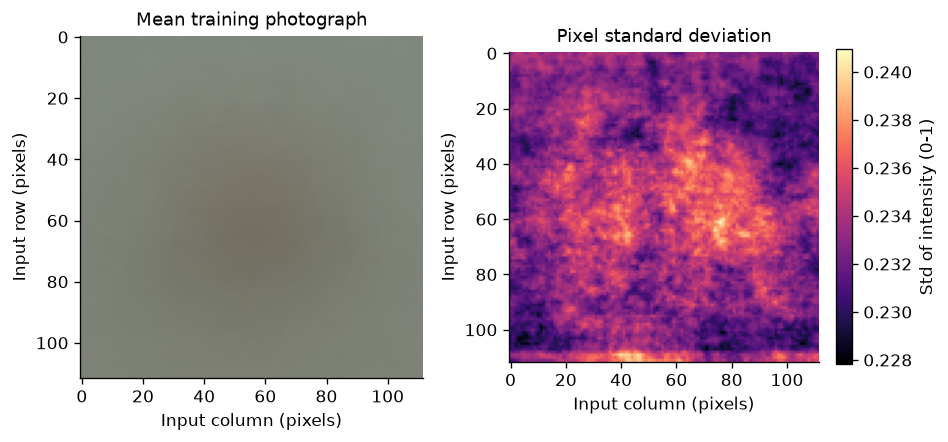

In [16]:
sample = train.sample(config.MOMENT_SAMPLE, random_state=config.RANDOM_SEED)["filename"]
mean_image, std_image = pixel_moments(sample)
fig = plot_moments(mean_image, std_image)
save_figure(fig, "moments", "eda")
plt.show()

**The average photograph is a featureless gray-green with a faintly warmer center, and the spread is almost flat:** the per-pixel standard deviation stays between about 0.23 and 0.24 across the whole input, so no region of the frame is the same from one photograph to the next. This is the opposite of a fixed-camera dataset: backgrounds, poses and lighting vary everywhere, and the only positional regularity is the bird sitting near the middle, which the box centers already showed. Per-class mean images would be just as blurred, because birds of one class face every direction, so the classes are explored through their embeddings in section 7 instead.

### A random look at the training photographs

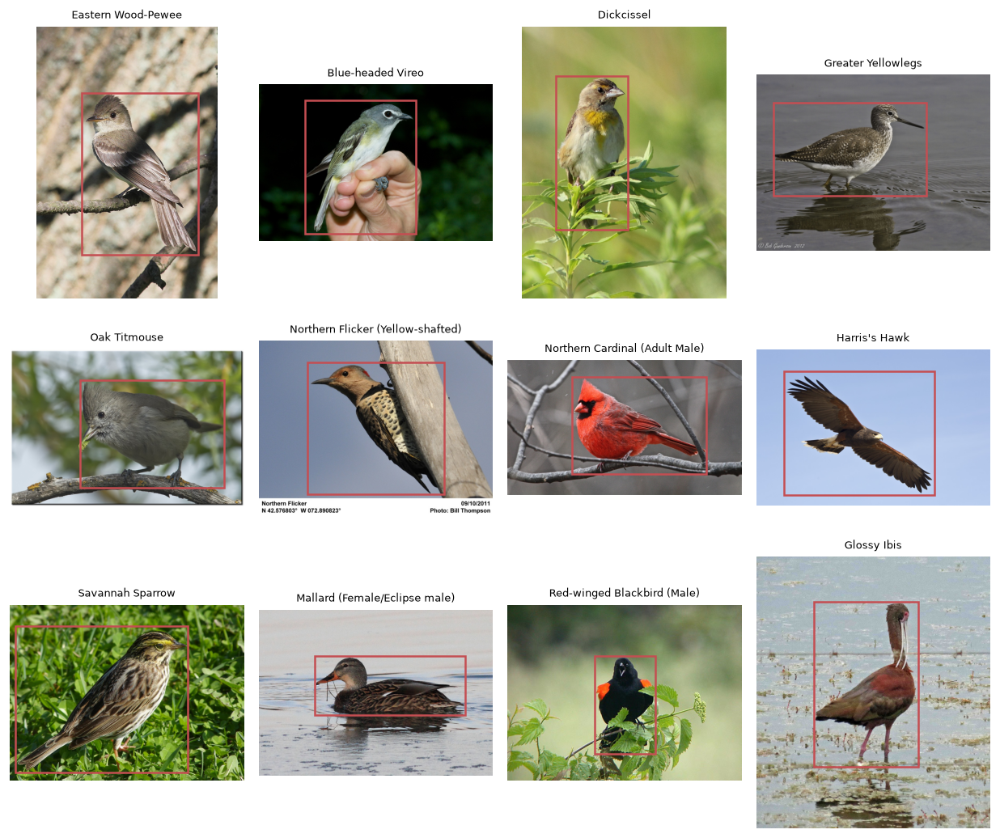

In [17]:
grid = train.sample(config.SAMPLE_GRID, random_state=config.RANDOM_SEED).merge(
    classes[["class_index", "class_name"]], on="class_index"
)
fig = image_grid(photo_panels(grid, grid["class_name"].tolist()), columns=config.GRID_COLUMNS)
save_figure(fig, "samples", "eda")
plt.show()

**A random draw shows what the models face:** birds perched, flying, wading and in hand (the Blue-headed Vireo is held by a bander), against bark, sky, water and foliage. Some photographs carry text, such as a caption with coordinates under the Northern Flicker and a photographer's watermark in the corner of the Greater Yellowlegs. A model could learn such marks as shortcuts, which is one of the things the LIME check in section 11 looks for.

## 7. Embeddings and the few-shot classifier

### How a pretrained network becomes a few-shot classifier

**Convolutional layers against fully connected layers:** a fully connected layer connects every input pixel to every output unit with its own weight, so a 224x224x3 input feeding even 1,000 units needs 150 million weights, and the layer has no notion that neighboring pixels belong together or that a beak is a beak wherever it appears. A convolutional layer instead slides a small filter (a 3x3 or 7x7 grid of weights per input channel) across the image and computes a dot product at every position. The same weights are reused everywhere (weight sharing), each output depends only on a small neighborhood (local connectivity), and a pattern detected in one corner is detected in any other (translation equivariance). That is why a CNN learns from far fewer examples than a fully connected network of the same depth.

**What the filters learn:** each filter's output is a feature map that is high wherever its pattern occurs. First-layer filters become edge, color and texture detectors; deeper layers combine them over growing receptive fields into parts (an eye ring, wing bars, a streaked breast) and finally into whole-object evidence. The classifier at the end only has to read out which part detectors fired.

**Residual connections:** ResNet-50, one of the backbones below, stacks 50 layers. In a plain deep stack the gradient reaching the early layers is a product of many per-layer Jacobians, and when those are small it shrinks exponentially with depth (the vanishing gradient), so the early layers stop learning and deeper plain networks train worse than shallower ones. A residual block computes `x + F(x)` instead of `F(x)`, so its Jacobian is `I + dF/dx`: the identity term gives the gradient a path through every block that never multiplies it toward zero, and a block that has nothing useful to add can learn `F = 0` and pass its input through. The same identity paths run through every transformer block of the vision transformers below.

**Vision transformers:** DINOv2 and CLIP's image encoder are vision transformers (ViT). A ViT cuts the image into 14x14 or 16x16 patches, embeds each as a vector, and lets every patch attend to every other through self-attention, so global context (the bird against its habitat, the head relative to the tail) is available from the first layer rather than only after many convolutions.

**Transfer learning:** a network pretrained on millions of images has already learned the generic part detectors above. Its penultimate layer, the embedding, is a description of the image in which similar-looking things sit close together. Three pretraining recipes are compared: ResNet-50 trained with ImageNet labels (supervised), CLIP trained to match 400 million images to their captions (language supervision), and DINOv2 trained without labels by self-distillation, where a student network learns to reproduce a teacher's output for different crops of the same image, which rewards features that identify the object and ignore the crop.

**Zero-shot, one-shot and few-shot:** zero-shot classification uses no labeled photograph at all; CLIP can do it by embedding a caption per class ("a photo of a Common Eider (Adult male), a type of bird.") and picking the caption closest to the image. One-shot and few-shot classification use one or a handful of labeled photographs per class. With a frozen embedding, the standard method is the one a prototypical network or a Siamese network uses at test time: average each class's labeled embeddings into a prototype and assign a new photograph to the class with the most similar prototype. No weight is trained, so a new class can be added by labeling a few photographs.

### Comparing the backbones on the same draws of labels

In [18]:
features = {name: cached_embeddings(name, audit["filename"]) for name in config.BACKBONES}
pool, validation_rows, test_rows = (frame.index.to_numpy() for frame in (train, val, test))


def draw(shots, seed):
    return draw_shots(train, shots, seed).to_numpy()

In [19]:
curves = compare_backbones(
    features, validation_rows, labels, draw, config.SHOT_CURVE, config.SHOT_SEEDS
)
display(
    curves.groupby(["backbone", "shots"])["accuracy"]
    .agg(["mean", "min", "max"])
    .unstack("backbone")
    .round(3)
)

mean                                  min                                  max                        
backbone clip_vit_b16 dinov2_vit_b14 resnet50 clip_vit_b16 dinov2_vit_b14 resnet50 clip_vit_b16 dinov2_vit_b14 resnet50
shots                                                                                                                  
1               0.272          0.542    0.175        0.260          0.522    0.172        0.295          0.558    0.180
2               0.388          0.636    0.233        0.376          0.629    0.219        0.402          0.646    0.242
3               0.459          0.698    0.278        0.444          0.686    0.270        0.466          0.706    0.284
5               0.528          0.747    0.333        0.517          0.742    0.320        0.539          0.756    0.349

{'accuracy': 0.441, 'top5_accuracy': 0.816, 'macro_f1': 0.388}


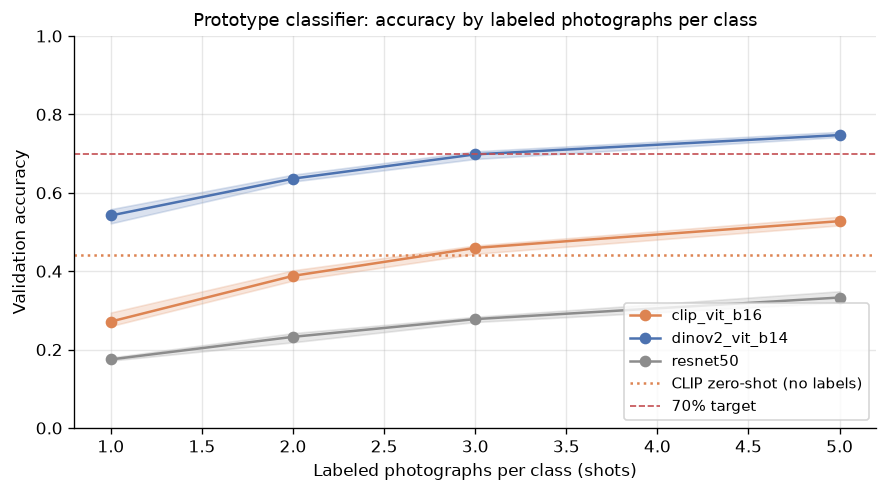

In [20]:
text_features = clip_text_embeddings(classes["class_name"])
zero_shot = classification_metrics(
    labels[validation_rows],
    zero_shot_scores(features["clip_vit_b16"][validation_rows], text_features),
)
print({name: round(value, 3) for name, value in zero_shot.items()})
fig = plot_shot_curves(curves, zero_shot["accuracy"])
save_figure(fig, "shot_curves", "fewshot")
plt.show()

**DINOv2 is the backbone, by a wide margin at every number of shots:** with one labeled photograph per class it reaches 54.2% validation accuracy, against 27.2% for CLIP and 17.5% for ResNet-50, and with five it reaches 74.7%, against 52.8% and 33.3%. The seed ranges are narrow (DINOv2's one-shot draws run from 52.2% to 55.8%), so the ranking is far outside the noise.

**Zero-shot is strongest when nothing is labeled, and it loses its edge quickly:** CLIP's captions (44.1% with no labeled photograph at all) beat CLIP's own prototypes at one and two shots, because the text tower knows more about a bird's name than one or two image embeddings can show, but three CLIP shots already pass it, and a single DINOv2 shot beats it by ten points.

**Why the backbones differ:** ResNet-50 was trained to separate ImageNet's 1,000 categories, only about 60 of them birds, so its embedding had no reason to keep the differences between two sparrows. DINOv2's self-distillation rewards features that tell any two images apart, which is exactly what comparing a photograph with prototypes needs.

### Testing the centering step

A common refinement of the prototype classifier (SimpleShot) subtracts the mean feature of the training pool before scaling features to unit length, which removes the direction every photograph shares so the cosine compares only what differs. The mean needs no labels, so a real unlabeled pool would allow it. The reflex is cheap to test: the same one-shot and five-shot draws, with and without centering, averaged over the five sampling seeds.

In [21]:
dino = features[config.FEWSHOT_BACKBONE]
centering = {
    name: shot_curve(
        dino,
        labels,
        draw,
        dino[validation_rows],
        labels[validation_rows],
        (config.START_SHOTS, config.MAX_SHOTS),
        config.SHOT_SEEDS,
        origin,
    )
    .groupby("shots")["accuracy"]
    .mean()
    for name, origin in (("centered", dino[pool].mean(axis=0)), ("not centered", None))
}
display(pd.DataFrame(centering).round(4))

,centered,not centered
shots,,
1,0.5424,0.5421
5,0.7466,0.7473


**Centering makes no measurable difference here, so the simpler classifier is kept:** one-shot accuracy is 54.24% centered against 54.21% plain, and five-shot accuracy is 74.66% against 74.73%, both differences far inside the seed range above. Every prototype classifier below only scales features to unit length.

### Which classes sit close together in the embedding

Fitting one prototype per class from every training label shows how separable the classes are for this backbone at best, and which ones crowd each other.

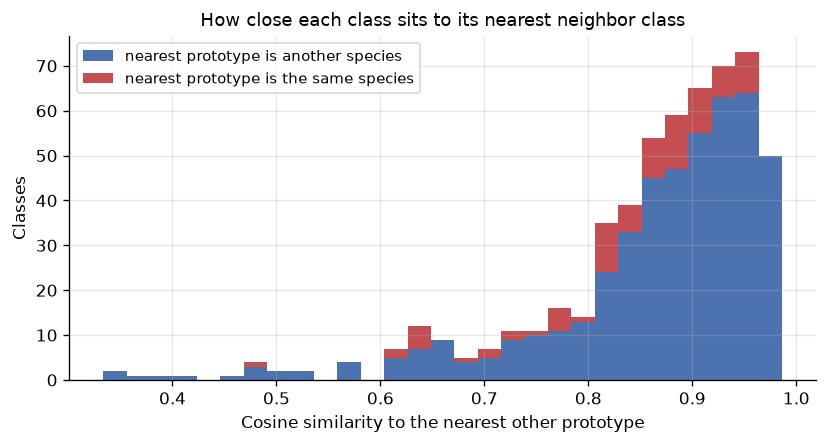

nearest prototype is the same species for 15.1% of all classes and 29.2% of the 288 classes that have a sibling plumage


,class_name,nearest,similarity,same_species
159,Semipalmated Sandpiper,Western Sandpiper,0.986,False
160,Western Sandpiper,Semipalmated Sandpiper,0.986,False
355,Carolina Chickadee,Black-capped Chickadee,0.982,False
356,Black-capped Chickadee,Carolina Chickadee,0.982,False
18,Greater Scaup (Breeding male),Lesser Scaup (Breeding male),0.981,False
19,Lesser Scaup (Breeding male),Greater Scaup (Breeding male),0.981,False
177,Western Screech-Owl,Eastern Screech-Owl,0.980,False
178,Eastern Screech-Owl,Western Screech-Owl,0.980,False


In [22]:
everyone = PrototypeClassifier.fit(dino[pool], labels[pool], len(classes))
neighbors = prototype_neighbors(everyone.prototypes, species)
fig = plot_prototype_neighbors(
    neighbors["similarity"].to_numpy(), neighbors["same_species"].to_numpy()
)
save_figure(fig, "prototype_neighbors", "fewshot")
plt.show()
has_sibling = classes.groupby("species")["class_index"].transform("size").to_numpy() > 1
same_share = neighbors["same_species"].mean()
sibling_share = neighbors.loc[has_sibling, "same_species"].mean()
print(
    f"nearest prototype is the same species for {same_share:.1%} of all classes and "
    f"{sibling_share:.1%} of the {has_sibling.sum()} classes that have a sibling plumage"
)
closest = neighbors.nlargest(config.CLOSEST_CLASS_PAIRS, "similarity").assign(
    class_name=lambda t: classes["class_name"].to_numpy()[t["class_index"]],
    nearest=lambda t: classes["class_name"].to_numpy()[t["nearest_class"]],
)
display(closest[["class_name", "nearest", "similarity", "same_species"]].round(3))

**The hardest pairs are look-alike species, not plumages of one species:** the nearest other prototype is the same species for only 15.1% of classes, and even among the 288 classes that have a sibling plumage, only 29.2% sit closest to that sibling. The tightest pairs are classic identification problems for birders: Semipalmated and Western Sandpiper (0.986), Carolina and Black-capped Chickadee (0.982), the breeding males of Greater and Lesser Scaup (0.981) and the two screech-owls (0.980). A prototype classifier separates two classes only as far as their prototypes are apart, so its errors should concentrate on pairs like these.

### Training the embedding on practice tasks

**What a prototypical or Siamese network adds:** the prototype classifier above compares photographs in an embedding that was never trained to compare birds. DINOv2 learned its features from 142 million unlabeled images, and the classifier only averages them. A prototypical network (Snell et al. 2017) trains the embedding for exactly this comparison, on a stream of small practice tasks called episodes: pick 50 classes, five labeled photographs of each (the support set) and five more to classify (the query set), average the support embeddings into one prototype per class, and update the embedding so that each query lands nearest its own class's prototype. A Siamese network (Koch et al. 2015) learns the same kind of embedding from pairs of photographs, same class or not; the prototypical network replaces the pair with a softmax over every class in the episode. Both are trained on base classes with plenty of labels and judged on novel classes they never saw, each with only a few labels, which is the situation the episodes rehearse.

**The test:** a small residual layer is trained on top of the frozen DINOv2 features. The backbone stays frozen, so this trains the last step of the embedding rather than the whole network. The layer's output weights start at zero, so before training it is the identity and reproduces the frozen classifier exactly. Species are split at random into base (60%), validation (20%) and novel (20%) classes, keeping every plumage of a species together, so the novel classes are new birds rather than the female of a male the layer was trained on. The layer learns from 1,000 episodes of base-class training photographs and keeps the weights with the best five-shot accuracy on the validation classes. The score is five-shot accuracy on the novel classes, using the same five photographs per class for the frozen and the trained embedding, over three species splits.

In [23]:
pool_features, pool_labels = dino[pool], labels[pool]
episodic = []
for seed in config.SPLIT_SEEDS:
    role = split_species(species, seed=seed)[pool_labels]
    shots = np.isin(pool, draw(config.MAX_SHOTS, seed))
    tasks = {
        name: (np.flatnonzero((role == name) & shots), np.flatnonzero((role == name) & ~shots))
        for name in ("validation", "novel")
    }
    base = role == "base"
    layer, layer_history = train_projection(
        pool_features[base],
        pool_labels[base],
        lambda candidate, task=tasks["validation"]: prototype_accuracy(
            pool_features, pool_labels, *task, candidate
        ),
        seed=seed,
    )
    episodic.append(
        {
            "split seed": seed,
            "novel classes": len(np.unique(pool_labels[tasks["novel"][0]])),
            "frozen DINOv2": prototype_accuracy(pool_features, pool_labels, *tasks["novel"]),
            "trained on base-class episodes": prototype_accuracy(
                pool_features, pool_labels, *tasks["novel"], layer
            ),
            "best episode": int(layer_history.loc[layer_history["monitor"].idxmax(), "episode"]),
        }
    )
episodic = pd.DataFrame(episodic)
display(episodic.round(4))
frozen_mean, trained_mean = (
    episodic["frozen DINOv2"].mean(),
    episodic["trained on base-class episodes"].mean(),
)
print(f"mean over the three splits: frozen {frozen_mean:.4f}, trained {trained_mean:.4f}")

,split seed,novel classes,frozen DINOv2,trained on base-class episodes,best episode
0,42,111,0.8917,0.9359,250
1,43,112,0.8563,0.8692,125
2,44,112,0.8539,0.8725,950


mean over the three splits: frozen 0.8673, trained 0.8926


**Training the embedding on base-class episodes helps on new birds, by a few points:** five-shot accuracy on the novel classes rises from 89.2% to 93.6% on the first species split, from 85.6% to 86.9% on the second and from 85.4% to 87.3% on the third, a gain of 2.5 points on average (86.7% to 89.3%). These accuracies sit above the 74.7% of the five-shot curve because each task separates only about 112 novel classes instead of all 555. The best weights come at very different points of training (episode 250, 125 and 950 of 1,000), each time chosen on validation classes the layer never trains on, which keeps it from simply specializing in the base species. The gain is modest because DINOv2's features already separate birds well; episodic training mainly reweights which of their directions matter for telling species apart.

**The same idea in this project's own setting:** here there are no base classes with plenty of labels, only the few labels per class. The second test trains the same layer on episodes drawn from the five labeled photographs per class of seed 42's draw (two as support and three as queries), keeps the weights with the best five-shot accuracy on validation, and scores five-shot prototypes over all 555 classes on validation and test.

In [24]:
five_rows = draw(config.MAX_SHOTS, config.RANDOM_SEED)
few_layer, few_history = train_projection(
    dino[five_rows],
    labels[five_rows],
    lambda candidate: prototype_accuracy(dino, labels, five_rows, validation_rows, candidate),
    shots=config.FEW_LABEL_SHOTS,
    queries=config.FEW_LABEL_QUERIES,
)
few_label = pd.DataFrame(
    {
        name: {
            "frozen DINOv2": prototype_accuracy(dino, labels, five_rows, rows),
            "trained on five-label episodes": prototype_accuracy(
                dino, labels, five_rows, rows, few_layer
            ),
        }
        for name, rows in (("validation", validation_rows), ("test", test_rows))
    }
)
display(few_label.round(4))
best_episode = int(few_history.loc[few_history["monitor"].idxmax(), "episode"])
print(f"weights kept from episode {best_episode} of {config.EPISODES}")

,validation,test
frozen DINOv2,0.7505,0.7217
trained on five-label episodes,0.7914,0.7656


weights kept from episode 300 of 1000


**In this project's own setting the same idea adds about four points:** trained on episodes drawn from the five labeled photographs per class, the layer lifts five-shot accuracy from 75.1% to 79.1% on validation and from 72.2% to 76.6% on test, with the weights kept from episode 300 of 1,000. The test gain matches the validation gain, so it is not an artifact of choosing the episode on validation. Averaging gives every direction of the embedding the same weight; the trained layer learns which directions separate these 555 classes, from nothing but the few labels the brief allows. DINOv2 does not need episodic training to reach the brief's target, but the few-shot classifier gets better with it, and section 10 scores it beside the others.

## 8. Labeling with the classifier's help

### Where the loop starts

The brief caps the starting labels at five per class. With DINOv2 features, five random labels per class already reach the 70% target on validation (the curve above), so a loop starting there would stop before its first round. The cap is a maximum, not a fixed number, so the loop starts from **one labeled photograph per class**: a one-shot classifier that becomes a few-shot one as confirmed labels accumulate.

### The loop

Each round:

1. Fit one prototype per class from the photographs labeled so far.
2. Score every unlabeled photograph in the training pool and keep, for each predicted class, the five most confident predictions (the "best predictions" of the brief). The quota is per class, because ranking the whole pool at once would spend every round on the easiest classes.
3. Show each proposal to the labeler next to labeled examples of the proposed class. A confirmed proposal joins the labeled set; a rejected one stays unlabeled and is never proposed for that class again.
4. Score the classifier on the combined test set and stop at 70%, as the brief specifies, with validation accuracy tracked beside it.

The labeler is simulated: the pool's own labels answer yes or no to each proposal and are read for nothing else, which is exactly the decision the brief describes ("visually comparing a few training images and target image"). A gallery of real proposals follows the loop so the decision can be seen.

**Two ways to define "most confident":** the top similarity (how close the photograph is to the prototype of its predicted class) and the margin (how much closer it is to that prototype than to the runner-up). The margin is the usual reflex, because a photograph close to two prototypes is ambiguous even when both similarities are high. Both are tested by running the whole loop once with each, stopping on the validation set so no test label takes part in the choice, and the ranking that reaches 70% with fewer labels and fewer reviews runs the brief's loop.

In [25]:
start = np.isin(pool, draw(config.START_SHOTS, config.RANDOM_SEED))
first = PrototypeClassifier.fit(dino[pool][start], labels[pool][start], len(classes))
monitors = {
    "validation": (dino[validation_rows], labels[validation_rows]),
    "test": (dino[test_rows], labels[test_rows]),
}
rankings = compare_rankings(
    dino[pool], labels[pool], start, monitors, config.PROPOSAL_RANKINGS, stop_on="validation"
)
display(rankings.round(4))

,ranking,rounds,labeled,reviewed,confirmed_share,validation_accuracy
0,margin,5,10153,12593,0.7622,0.7021
1,similarity,3,6702,7901,0.7780,0.7113


**Ranking by similarity clearly beats the margin reflex:** stopping on validation, the similarity ranking reaches 70% in 3 rounds with 6,702 labeled photographs and 7,901 proposals reviewed, while the margin needs 5 rounds, 10,153 labels and 12,593 reviews, and the labeler confirms a smaller share of what it shows (76.2% against 77.8%). A high margin can come from a photograph that is far from every prototype but slightly less far from one, an odd image the classifier happens to be decisive about. A high similarity requires the photograph to look like the class's labeled examples, so its proposals are more often right and more typical of the class. Similarity therefore runs the brief's loop.

In [26]:
ranking = rankings.loc[rankings["labeled"].idxmin(), "ranking"]
loop = labeling_loop(dino[pool], labels[pool], start, monitors, rank_by=ranking)
print(f"ranking used: {ranking}")
display(loop.history.round(3))

ranking used: similarity


,round,labeled,label_noise,validation_accuracy,test_accuracy,proposed,accepted,precision
0,0,555,0.0,0.540,0.536,NaN,NaN,NaN
1,1,2599,0.0,0.646,0.646,2704.0,2044.0,0.756
2,2,4701,0.0,0.690,0.685,2629.0,2102.0,0.800
3,3,6702,0.0,0.711,0.702,2568.0,2001.0,0.779


**The loop crosses 70% on the test set in round 3:** it starts from 555 labeled photographs (one per class, 53.6% test accuracy), each round proposes about 2,600 photographs of which the labeler confirms 76% to 80%, and the labeled set grows to 2,599, 4,701 and 6,702. Test accuracy rises to 64.6%, 68.5% and 70.2%, where the brief's stopping rule ends the loop. Validation accuracy tracks it within a point every round (71.1% at the end), and stopping on validation would have ended the loop in the same round, so the test-based rule did not change the outcome.

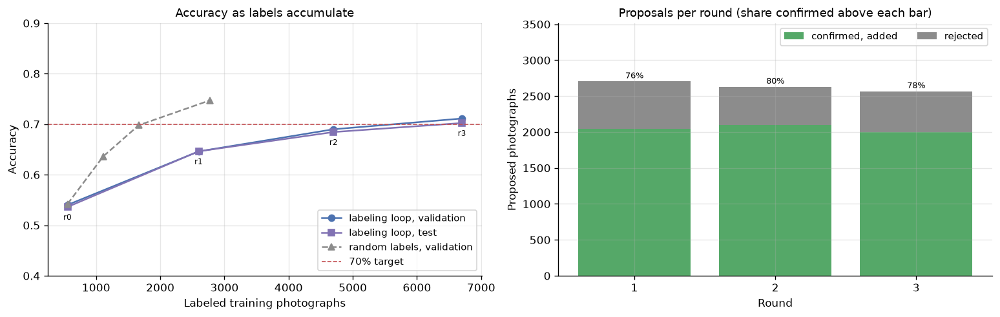

In [27]:
random_reference = (
    curves[curves["backbone"] == config.FEWSHOT_BACKBONE]
    .groupby("shots")[["labeled", "accuracy"]]
    .mean()
)
fig = plot_labeling_history(loop.history, random_reference)
save_figure(fig, "labeling_history", "fewshot")
plt.show()

**The loop is far less label-efficient than labeling at random:** three random labels per class (1,665 photographs) already reach 69.8% on validation and five (2,774) reach 74.7%, while the loop needs 6,702 confirmed labels to reach 71.1%. The reason is built into the brief's rule. The most confident predictions are photographs that already look like the labeled examples, so confirming them adds labels that barely move each prototype; a random photograph is as likely to show the class from a new angle, in new light or in another plumage, which is what the prototype was missing. What the loop saves is effort per label, not the number of labels: the labeler answers yes or no next to examples instead of choosing among 555 names.

### What the labeler sees

Proposals from the final round, each next to three photographs already labeled with the class it was proposed for. A green frame is a confirmed proposal, a gray one a rejection.

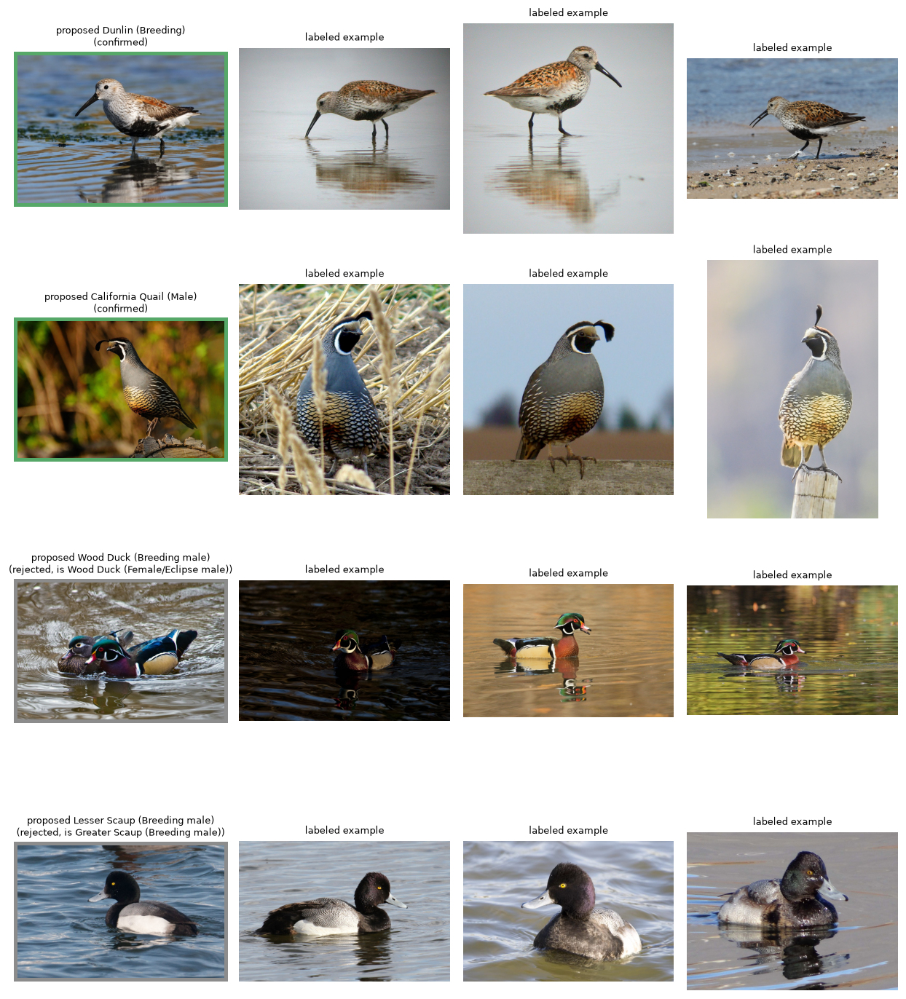

In [28]:
last_round = int(loop.proposals["round"].max())
cases = verification_cases(
    loop,
    start,
    labels[pool],
    train["filename"].to_numpy(),
    classes["class_name"].to_numpy(),
    last_round,
    config.GALLERY_PROPOSALS // 2,
    config.GALLERY_REFERENCES,
)
fig = verification_grid(cases)
save_figure(fig, "verification", "fewshot")
plt.show()

**The gallery shows what each decision looks like:** a breeding-plumage Dunlin and a male California Quail match their labeled examples and are confirmed. The rejections are the instructive part. One photograph proposed as a breeding male Wood Duck shows a breeding male swimming beside a female and carries the female's label, so the photograph is ambiguous rather than the classifier wrong; the other, proposed as a Lesser Scaup, is a Greater Scaup, a pair section 7 found among the closest prototypes. A real labeler would face the same judgment calls, which is why confirming a proposal is a decision and not a formality.

In [29]:
loop_rows = pool[loop.labeled]
per_class = np.bincount(labels[loop_rows], minlength=len(classes))
reviewed, confirmed = int(loop.history["proposed"].sum()), int(loop.history["accepted"].sum())
print(
    f"reviewed {reviewed:,} proposals and confirmed {confirmed:,}; "
    f"labeled set {len(loop_rows):,} ({len(loop_rows) / len(pool):.1%} of the pool), "
    f"per class min {per_class.min()}, median {np.median(per_class):.0f}, max {per_class.max()}"
)

reviewed 7,901 proposals and confirmed 6,147; labeled set 6,702 (31.4% of the pool), per class min 1, median 14, max 16


**The labeled set is balanced but capped:** the loop reviewed 7,901 proposals and confirmed 6,147, ending with 6,702 labeled photographs, 31.4% of the pool, a median of 14 per class. At least one class never gained a label beyond its starting photograph, and the quota of five proposals per class and round caps every class at 16 after three rounds.

### What if the labeler makes mistakes?

The loop above trusts a labeler who never errs: the pool's own labels answer every proposal. A person comparing a proposal with a few labeled examples does err, and the error that matters is confirming a wrong proposal, because that photograph then joins the prototype of the wrong class. A wrong label stays in the labeled set and pulls later rounds' prototypes, and so later rounds' proposals, toward the wrong class. Five simulated labelers measure how much the result moves:

- the brief's labeler, who never errs;
- three careless labelers, who confirm a wrong proposal, and reject a right one, 5%, 10% or 20% of the time;
- a labeler fooled by look-alikes, who confirms half of the wrong proposals whose class is another plumage of the true species or the true class's nearest neighbor in the embedding (section 7), and 5% of the other wrong ones.

Each runs the brief's loop for 12 rounds, past the 70% target, five times with different random mistakes.

the brief's loop made 1,754 wrong proposals; 56.9% of them proposed a look-alike class


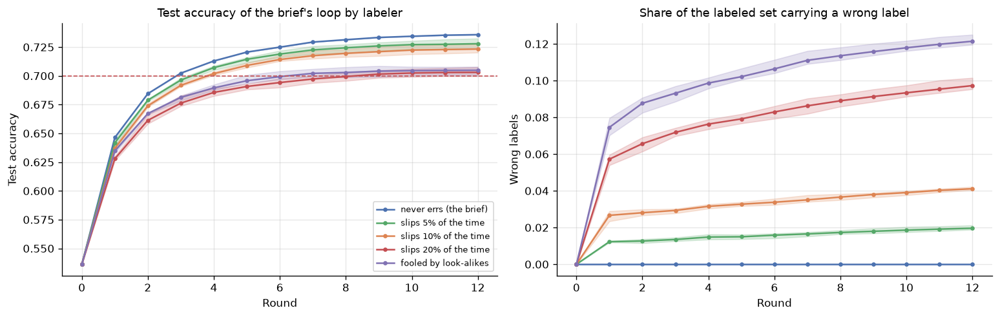

In [30]:
lookalikes = lookalike_matrix(species, neighbors["nearest_class"].to_numpy())
wrong = loop.proposals[~loop.proposals["accepted"]]
lookalike_share = lookalikes[wrong["true"].to_numpy(), wrong["predicted"].to_numpy()].mean()
print(
    f"the brief's loop made {len(wrong):,} wrong proposals; "
    f"{lookalike_share:.1%} of them proposed a look-alike class"
)
labelers = {
    "never errs (the brief)": oracle,
    **{f"slips {slip:.0%} of the time": careless_labeler(slip) for slip in config.LABELER_SLIPS},
    "fooled by look-alikes": careless_labeler(
        config.LABELER_SLIPS[0], config.LOOKALIKE_SLIP, lookalikes
    ),
}
robustness = labeler_robustness(
    dino[pool], labels[pool], start, monitors, labelers, config.LABELER_SEEDS, config.LABELER_ROUNDS
)
fig = plot_labeler_robustness(robustness)
save_figure(fig, "labeler_robustness", "fewshot")
plt.show()

In [31]:
by_round = robustness.groupby(["labeler", "round"], sort=False)[
    ["test_accuracy", "label_noise", "labeled"]
].mean()
reached = first_round_reaching(robustness, "test_accuracy").groupby("labeler", sort=False)
stop_round = int(loop.history["round"].max())
labeler_table = pd.concat(
    {
        f"round {stop_round}": by_round.xs(stop_round, level="round"),
        f"round {config.LABELER_ROUNDS}": by_round.xs(config.LABELER_ROUNDS, level="round"),
    },
    axis=1,
)
labeler_table[("reaches 70% on test", "runs")] = reached.size().reindex(
    labeler_table.index, fill_value=0
)
labeler_table[("reaches 70% on test", "first round")] = reached["round"].mean()
labeler_table[("reaches 70% on test", "labeled")] = reached["labeled"].mean()
display(labeler_table.round(3))

round 3                          round 12                      reaches 70% on test                     
                       test_accuracy label_noise labeled test_accuracy label_noise  labeled                runs first round  labeled
labeler                                                                                                                             
never errs (the brief)         0.702       0.000  6702.0         0.736       0.000  16313.0                   5         3.0   6702.0
slips 5% of the time           0.696       0.013  6445.8         0.728       0.020  15655.8                   5         4.0   8228.0
slips 10% of the time          0.692       0.029  6179.6         0.723       0.041  15077.6                   5         4.0   7899.2
slips 20% of the time          0.676       0.072  5699.8         0.703       0.097  13812.4                   4         9.0  12474.5
fooled by look-alikes          0.681       0.093  6870.8         0.705       0.121  16685.6                   5         7.0  13240.4

**Mistakes cost rounds, and look-alike mistakes cost the most:** of the 1,754 wrong proposals in the brief's loop, 56.9% proposed a look-alike class, so the mistake a person is most likely to make is also the most common one on offer. A labeler who slips 5% or 10% of the time leaves 1.3% and 2.9% of the labeled set wrong after three rounds and reaches 70% on test one round later than the error-free labeler (8,228 and 7,899 labels instead of 6,702). At 20% slips, or when half the look-alike proposals get through, 7.2% and 9.3% of the labels are wrong by round 3, the loop needs nine and seven rounds on average and about twice the labels to reach 70%, and one of the five runs with 20% slips never gets there in twelve rounds.

The damage compounds instead of washing out: the share of wrong labels keeps growing, to 9.7% and 12.1% by round 12, because a wrong label pulls its prototype toward the wrong class, and that prototype then proposes more photographs of the wrong class. Those two loops flatten around 70% (70.3% and 70.5% in round 12) while the error-free loop keeps climbing to 73.6%. Label quality matters as much as label count here, which argues for auditing a sample of each round's confirmations, starting with the look-alike pairs.

### Would uncertain or random proposals do better?

The brief's rule shows the labeler the classifier's most confident predictions and keeps only the confirmations, and section 8 found it label-hungry, because confident photographs resemble what is already labeled. Active learning (Settles 2009) usually does the opposite: it asks about the photographs the classifier is least sure of, and the labeler names their class, so a wrong guess becomes a corrected label instead of a rejection. Four selection rules are compared under that protocol, each with the same budget per round (two photographs per class, 1,110 in all) for eight rounds from the same one-shot start:

- confident, the brief's rule with corrections: the two most similar photographs per predicted class;
- uncertain: the 1,110 photographs with the smallest margin between their two best classes, wherever they are;
- random: 1,110 photographs drawn at random from the pool;
- mixed: one confident photograph per predicted class, and the rest drawn at random.

The brief's confirm-only loop with the same quota is drawn for reference. Validation accuracy is the judge, and every rule runs with three seeds (only random and mixed draw anything at random).

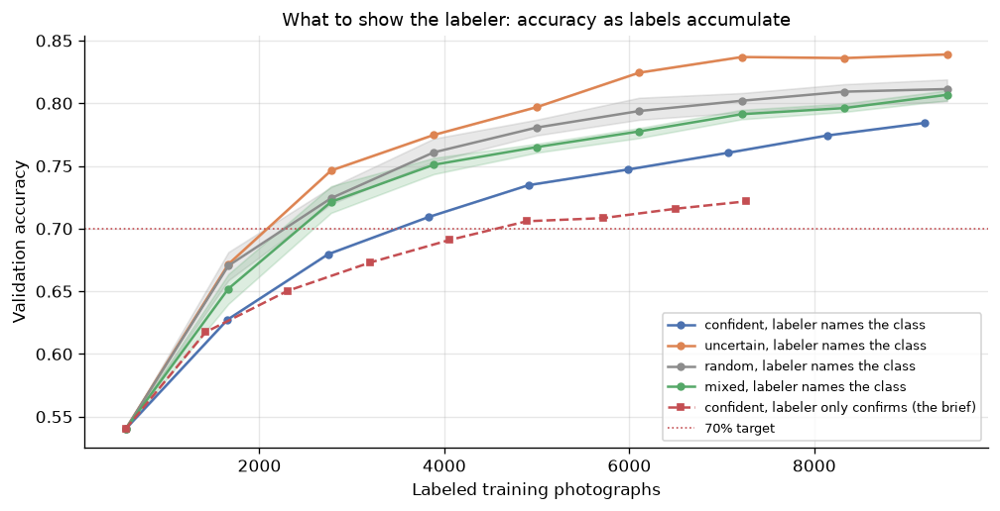

,"labeled, round 2","accuracy, round 2","labeled, round 4","accuracy, round 4","labeled, round 8","accuracy, round 8"
confident,2743.0,0.680,4909.0,0.735,9193.0,0.784
uncertain,2775.0,0.746,4995.0,0.797,9435.0,0.839
random,2775.0,0.724,4995.0,0.781,9435.0,0.811
mixed,2775.0,0.721,4995.0,0.765,9435.0,0.807
confirm only (the brief),2307.0,0.650,4053.0,0.691,7262.0,0.722


In [32]:
strategies = pd.concat(
    [
        labeling_with_answers(
            dino[pool],
            labels[pool],
            start,
            monitors["validation"],
            strategy,
            config.QUERY_ROUNDS,
            config.QUERY_PER_CLASS,
            seed,
        )
        for strategy in config.QUERY_STRATEGIES
        for seed in config.QUERY_SEEDS
    ],
    ignore_index=True,
)
# The brief's confirm-only loop with the same quota, run for every round instead of stopping at 70%.
confirm_only = labeling_loop(
    dino[pool],
    labels[pool],
    start,
    {"validation": monitors["validation"]},
    stop_on="validation",
    target=np.inf,
    per_class=config.QUERY_PER_CLASS,
    max_rounds=config.QUERY_ROUNDS,
).history
fig = plot_query_strategies(strategies, confirm_only)
save_figure(fig, "query_strategies", "fewshot")
plt.show()
brief = confirm_only.rename(columns={"validation_accuracy": "accuracy"})
compared_runs = [*strategies.groupby("strategy", sort=False), ("confirm only (the brief)", brief)]
strategy_table = pd.DataFrame(
    {
        strategy: {
            f"{column}, round {round_number}": runs_of_strategy.groupby("round")[column].mean()[
                round_number
            ]
            for round_number in config.QUERY_REPORT_ROUNDS
            for column in ("labeled", "accuracy")
        }
        for strategy, runs_of_strategy in compared_runs
    }
).T
display(strategy_table.round(3))

**Asking about the uncertain photographs wins at every budget, and correcting beats rejecting:** after two rounds (about 2,800 labels) the uncertain rule reaches 74.6% on validation, random 72.4%, mixed 72.1% and confident 68.0%, and after eight rounds (about 9,400 labels) the order holds at 83.9%, 81.1%, 80.7% and 78.4%. The smallest margins sit between look-alike classes, which is exactly where the prototypes need examples, and with the true class supplied, each such photograph moves the right prototype away from its neighbor. Confident photographs resemble what is already labeled, the finding of section 8, and adding random photographs to them (the mixed rule) recovers most of random's lead.

The protocol matters as much as the selection: the brief's confirm-only loop sits below every rule in the figure and ends at 72.2% after eight rounds and 7,262 labels, while the same confident proposals with corrections reach 78.4%. Uncertainty sampling also has a cost the figure does not show: the photographs it picks are the hardest for a person to name, and naming one of 555 classes is slower expert work than confirming a suggestion. Under the brief's confirm-only protocol the loop is cheap per label but needs many labels; with an expert who can name classes, the uncertain photographs are the better use of each label.

## 9. The uptrained classifier

**What the brief asks for:** take the fully labeled training set (all 21,364 training photographs with their labels, as opposed to the few labels the loop started from) and tune a pretrained architecture to it, training the classification head first and then fine-tuning the backbone.

**Architecture:** the same DINOv2 ViT-B/14 the few-shot classifier uses. Keeping the backbone fixed across the comparison means the difference between the two approaches is the training and the labels, not a different network. The classification head is one linear layer from the 768-dimensional embedding to 555 logits, with dropout in front. A deeper head would add capacity the problem does not need: the prototype results already show the classes are close to linearly separable in this embedding, and with about forty photographs per class an extra hidden layer mostly adds a way to overfit.

**Loss and optimizer:** softmax cross-entropy, the negative log-probability of the correct class, which is the right loss for one label out of many. Label smoothing of 0.1 moves a little of the target probability from the correct class to the others, which stops the network from pushing logits toward infinity on training photographs, useful here because several classes are near-duplicates of each other. It also holds the network's confidence below its accuracy, which section 10 measures and corrects. The optimizer is AdamW: for each weight it keeps running averages of the gradient (first moment) and of its square (second moment) and steps by the first divided by the square root of the second, so each weight gets its own step size, and it applies weight decay directly to the weights instead of through the gradient, which keeps the decay from being rescaled by those adaptive step sizes.

### Stage one: training the head on frozen features

The backbone's features are cached, so one training run takes seconds and the head's learning rate, weight decay and dropout can be searched jointly with Optuna (a TPE sampler, seeded) instead of one at a time. Every run keeps the epoch with the best validation accuracy.

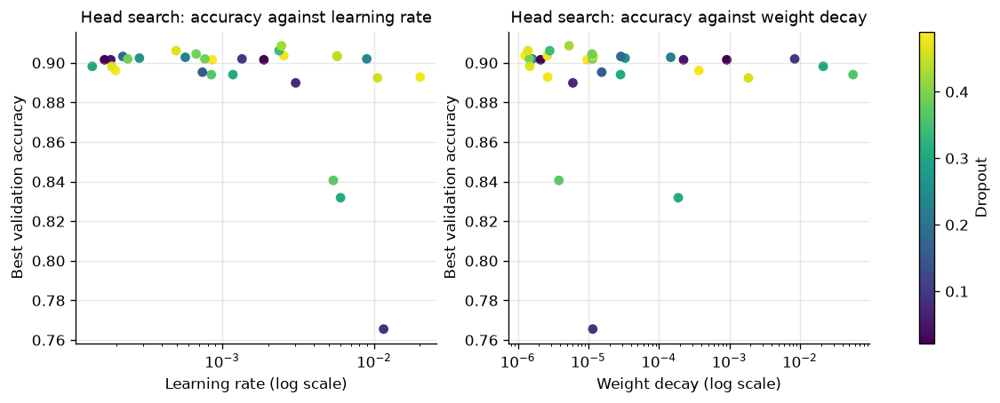

{'lr': 0.00245, 'weight_decay': 5.32e-06, 'dropout': 0.425} best validation accuracy 0.9086


In [33]:
head_dir = config.MODEL_DIR / "head"
train_xy, val_xy = (dino[pool], labels[pool]), (dino[validation_rows], labels[validation_rows])
study = tune_head(train_xy, val_xy, head_dir, len(classes))
trials = study.trials_dataframe().rename(columns=lambda column: column.replace("params_", ""))
fig = plot_head_search(trials)
save_figure(fig, "head_search", "training")
plt.show()
print(
    {name: float(f"{value:.3g}") for name, value in study.best_params.items()},
    f"best validation accuracy {study.best_value:.4f}",
)

**The head is insensitive to its hyperparameters over a wide range:** most of the 30 trials land between about 0.89 and 0.91 validation accuracy across learning rates from about 1e-4 to 2e-2 and weight decays from 1e-6 to 5e-2, and the best (90.86%, at learning rate 0.00245, weight decay 5.3e-6 and dropout 0.425) is a fraction of a point above a typical trial. The three clear failures use learning rates above about 5e-3, where the step overshoots before the cosine schedule brings it down, though other trials at similar rates survive. The search confirms the head rather than rescues it: the features are already close to linearly separable.

**Testing the class-balance reflex:** training classes range from 4 to 54 photographs. Weighting the loss by inverse class frequency is the usual reflex for imbalance, so the best head is trained both ways and kept only if validation rewards it.

In [34]:
heads = {
    name: fit_head(
        train_xy,
        val_xy,
        study.best_params,
        head_dir,
        f"head_{name}",
        len(classes),
        balanced=balanced,
    )[0]
    for name, balanced in (("plain", False), ("balanced", True))
}
balance = pd.DataFrame(
    {
        name: classification_metrics(
            labels[validation_rows], head_scores(model, dino[validation_rows])
        )
        for name, model in heads.items()
    }
)
display(balance.round(4))

,plain,balanced
accuracy,0.9086,0.9040
top5_accuracy,0.9846,0.9858
macro_f1,0.8868,0.8888


**Class weighting is not kept:** the plain head reaches 90.86% validation accuracy against 90.40% weighted, while the weighted head gains a little on macro F1 (88.88% against 88.68%) and top-5 accuracy (98.58% against 98.46%). Accuracy is the primary metric, and the classes are only mildly imbalanced (4 to 54 training photographs, median 40), so the plain head is used.

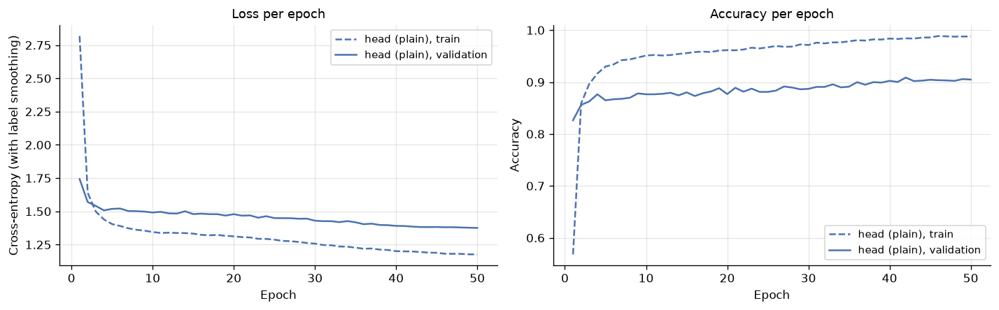

In [35]:
head_name = balance.loc["accuracy"].idxmax()
head = heads[head_name]
fig = plot_learning_curves({f"head ({head_name})": read_history(head_dir, f"head_{head_name}")})
save_figure(fig, "head_learning_curves", "training")
plt.show()

**The head learns most of what it will learn in the first few epochs:** validation accuracy passes 0.86 by the second epoch and creeps up to its best near epoch 42, while training accuracy keeps climbing toward 0.99. The widening gap is the head beginning to memorize, and the checkpoint keeps the best validation epoch, not the last. The loss stays above 1 even on training photographs because label smoothing never lets the target probability reach 1.

**The loop's labels alone:** the same head trained only on the photographs the labeling loop confirmed shows what those labels are worth when a model is trained on them instead of averaged into prototypes.

In [36]:
loop_head, _ = fit_head(
    (dino[loop_rows], labels[loop_rows]),
    val_xy,
    study.best_params,
    head_dir,
    "head_loop_labels",
    len(classes),
)
display(
    pd.Series(
        classification_metrics(
            labels[validation_rows], head_scores(loop_head, dino[validation_rows])
        )
    ).round(4)
)

accuracy         0.7326
top5_accuracy    0.8769
macro_f1         0.6938
dtype: float64

**Trained on the loop's labels alone, the same head reaches 73.3% on validation:** that is 2.1 points above the loop's own prototypes (71.1%) on the same 6,702 photographs, so learning a weight per class helps even with this few labels, and 17.6 points below the head trained on all 21,364.

### Stage two: fine-tuning the backbone

The fine-tuned network starts from the stage-one head (linear probing, then fine-tuning). A randomly initialized head would send large, noisy gradients into the pretrained blocks during the first steps and distort the features before the head had learned anything; starting from a trained head keeps the early gradients small and meaningful.

The top four of the twelve transformer blocks, the final layer norm and the head are trained; the first eight blocks stay frozen. The early blocks compute generic patterns that transfer unchanged, freezing them skips two thirds of the backward pass on this laptop GPU, and it leaves fewer weights free to overfit about forty photographs per class. Learning rates fall by a factor of 0.75 per block going down (layer-wise decay), so the blocks nearest the head adapt most. The schedule warms up linearly over the first 10% of steps, then follows a cosine down to zero, and training images get random crops, horizontal flips and mild brightness, contrast and saturation changes.

**Choosing the learning rate:** a full run takes about an hour, so four learning rates (1e-5, 3e-5, 1e-4 and 3e-4) are first compared on a short version of the problem, one epoch on a quarter of the training set. This is a one-factor check, conditional on the other settings.

In [37]:
finetune_dir = config.MODEL_DIR / "finetune"
subset = train.groupby("class_index").sample(
    frac=config.TUNING_FRACTION, random_state=config.RANDOM_SEED
)
subset_files = (subset["filename"].to_numpy(), subset["class_index"].to_numpy())
val_files = (val["filename"].to_numpy(), labels[validation_rows])
lr_check = {
    lr: fine_tune(
        subset_files,
        val_files,
        head,
        config.FEWSHOT_BACKBONE,
        len(classes),
        lr,
        finetune_dir,
        f"short_lr_{lr:g}",
        max_epochs=config.TUNING_EPOCHS,
    )[1]
    for lr in config.FINETUNE_LRS
}
display(
    pd.Series(
        lr_check, name="validation accuracy, one epoch on a quarter of the training set"
    ).round(4)
)

0.00001    0.9011
0.00003    0.8907
0.00010    0.8815
0.00030    0.8160
Name: validation accuracy, one epoch on a quarter of the training set, dtype: float64

**The short check prefers whichever rate moves the network least, so it cannot pick one:** after one epoch on a quarter of the training set, validation accuracy falls steadily as the rate rises, from 90.11% at 1e-5 through 89.07% at 3e-5 and 88.15% at 1e-4 to 81.60% at 3e-4, and every rate sits below the trained head's 90.86%. One short epoch is not enough for the unfrozen blocks to recover from their first steps on augmented crops, so the network that stays closest to the trained head wins, and a rate small enough to change nothing would win outright. The check measures disturbance, not where a full run ends. The first version of this notebook took 3e-5 from it, the better of the two rates it compared then; the recipe below keeps 3e-5, and the next subsection settles the question with full-length runs at 1e-5 and 1e-4.

In [38]:
train_files = (train["filename"].to_numpy(), labels[pool])
finetuned, finetuned_val = fine_tune(
    train_files,
    val_files,
    head,
    config.FEWSHOT_BACKBONE,
    len(classes),
    config.FINETUNE_LR,
    finetune_dir,
    "recipe_seed42",
)
history = read_history(finetune_dir, "recipe_seed42")
display(history[["epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy"]].round(4))
print(
    f"{trainable_share(finetuned):.1%} of the weights trained; "
    f"best validation accuracy {finetuned_val:.4f}"
)

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,0,1.5491,0.8817,1.4611,0.8844
1,1,1.4105,0.9173,1.3724,0.9040
2,2,1.2696,0.9575,1.3003,0.9295
3,3,1.2105,0.9740,1.2888,0.9307


33.4% of the weights trained; best validation accuracy 0.9307


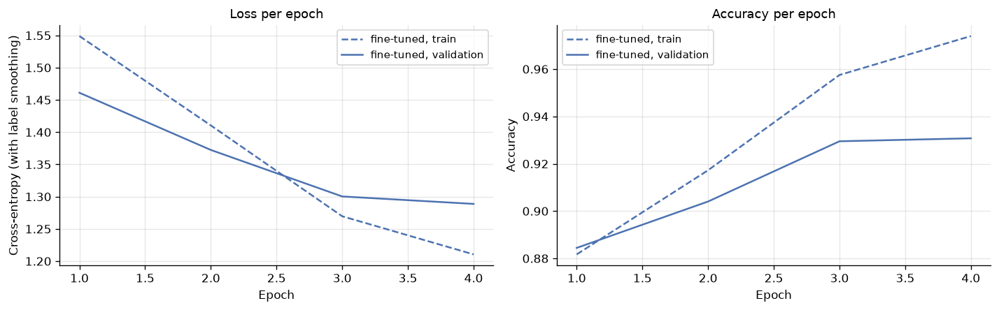

In [39]:
fig = plot_learning_curves({"fine-tuned": history})
save_figure(fig, "finetune_learning_curves", "training")
plt.show()

**Fine-tuning adds 2.2 points on validation:** accuracy rises from 88.44% after the first epoch, while the warm-up and the augmented crops are still unsettling the head, to 93.07% after the fourth, above the head's 90.86%. Training accuracy (97.40%) runs ahead of validation, so the network is starting to fit its own photographs more closely than new ones, and the gain flattens as the cosine schedule ends (92.95% to 93.07% over the last epoch). 33.4% of the weights are updated: the top four blocks, the final layer norm and the head. The best epoch is the checkpoint kept; the next subsection decides whether this run or a variant of it is the network evaluated in section 10.

### How much is left in the recipe?

The recipe above is a single run: four epochs, the top four blocks, one learning rate and seed 42, and its training accuracy was still climbing when the schedule ended. Six more full runs test it, each changing one thing:

- seeds 43 and 44 with the same recipe, which changes only the shuffling, the augmented crops and the dropout masks, and shows how far two identical recipes land apart;
- eight epochs instead of four, with the warm-up and the cosine stretched over the longer run;
- all twelve blocks unfrozen instead of four, which is full fine-tuning from the same trained head with the same layer-wise decay (the first block moves at 0.75 to the twelfth power, about 3% of the head's rate);
- learning rates of 1e-5 and 1e-4 at full length, one on each side of 3e-5, since only a full run can rank them.

Each run keeps its best validation epoch, and validation decides. A variant replaces the recipe only if its validation accuracy beats the recipe's three-seed mean by more than the recipe's own seed-to-seed range, since a smaller gain could come from the seed alone. Their test scores are read in section 10.

In [40]:
recipe = {
    "base_lr": config.FINETUNE_LR,
    "max_epochs": config.FINETUNE_EPOCHS,
    "unfrozen_blocks": config.UNFROZEN_BLOCKS,
    "seed": config.RANDOM_SEED,
}
settings = {f"recipe_seed{seed}": {**recipe, "seed": seed} for seed in config.FINETUNE_SEEDS}
settings |= {name: {**recipe, **change} for name, change in config.FINETUNE_VARIANTS.items()}
rows = []
for name, setting in settings.items():
    _, best_val = fine_tune(
        train_files,
        val_files,
        head,
        config.FEWSHOT_BACKBONE,
        len(classes),
        log_dir=finetune_dir,
        name=name,
        **setting,
    )
    rows.append(
        {
            "run": name,
            "group": "recipe" if name.startswith("recipe") else "variant",
            **setting,
            "validation_accuracy": best_val,
        }
    )
runs = pd.DataFrame(rows)
recipe_runs = runs[runs["group"] == "recipe"]
spread = recipe_runs["validation_accuracy"].max() - recipe_runs["validation_accuracy"].min()
bar = recipe_runs["validation_accuracy"].mean() + spread
best_variant = runs[runs["group"] == "variant"].nlargest(1, "validation_accuracy").iloc[0]
final_run = best_variant["run"] if best_variant["validation_accuracy"] > bar else "recipe_seed42"
display(runs.round({"validation_accuracy": 4}))
recipe_mean = recipe_runs["validation_accuracy"].mean()
print(
    f"recipe over three seeds: mean {recipe_mean:.4f}, range {spread:.4f}; "
    f"a variant must exceed {bar:.4f}; the model carried forward is {final_run}"
)

,run,group,base_lr,max_epochs,unfrozen_blocks,seed,validation_accuracy
0,recipe_seed42,recipe,0.00003,4,4,42,0.9307
1,recipe_seed43,recipe,0.00003,4,4,43,0.9282
2,recipe_seed44,recipe,0.00003,4,4,44,0.9249
3,epochs_8,variant,0.00003,8,4,42,0.9345
4,blocks_12,variant,0.00003,4,12,42,0.9191
5,lr_1e-05,variant,0.00001,4,4,42,0.9216
6,lr_0.0001,variant,0.00010,4,4,42,0.9303


recipe over three seeds: mean 0.9280, range 0.0058; a variant must exceed 0.9338; the model carried forward is epochs_8


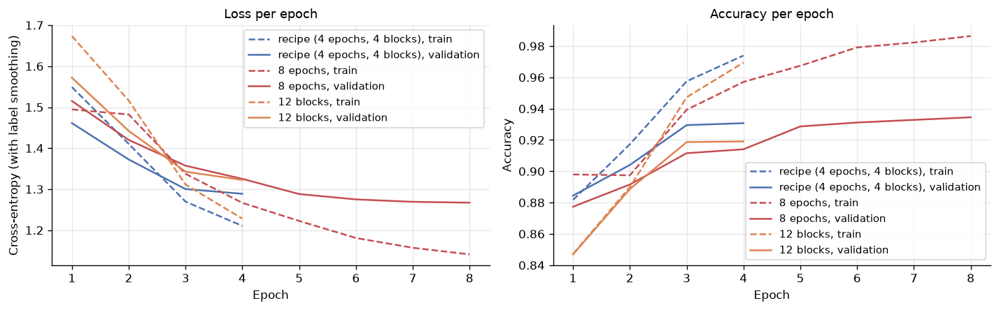

In [41]:
fig = plot_learning_curves(
    {
        "recipe (4 epochs, 4 blocks)": history,
        "8 epochs": read_history(finetune_dir, "epochs_8"),
        "12 blocks": read_history(finetune_dir, "blocks_12"),
    }
)
save_figure(fig, "finetune_variant_curves", "training")
plt.show()
if final_run != "recipe_seed42":
    finetuned, finetuned_val = fine_tune(
        train_files,
        val_files,
        head,
        config.FEWSHOT_BACKBONE,
        len(classes),
        log_dir=finetune_dir,
        name=final_run,
        **settings[final_run],
    )

**Only the longer schedule clears the bar, and only just:** the recipe's three seeds reach 93.07%, 92.82% and 92.49% on validation (mean 92.80%, range 0.58 points), so a variant needs more than 93.38%. Eight epochs reach 93.45% and become the network carried forward to section 10. The learning curves show how: after four epochs the eight-epoch run is behind the recipe, because its learning rate is still high at that point, and it passes the recipe in the second half as the longer cosine decays. Its training accuracy keeps pulling away from validation, so a few more epochs would mostly fit the training photographs.

The other variants lose. All twelve blocks unfrozen reach 91.91%, below every seed of the recipe: the first steps disturb the low-level features, as the low first epoch in the figure shows, and four epochs are not enough to recover. The learning rate turns out flat around the recipe's 3e-5: 1e-4 reaches 93.03%, inside the recipe's seed range, and 1e-5 (92.16%) is too small a step for four epochs. So the recipe's rate sits in the middle of its bracket, and the short check's preference for 1e-5 was the artifact described above.

### The same two stages on a convolutional network

ResNet-50 (He et al. 2016) is the convolutional network of the sprint's material: residual blocks of convolutions and batch normalization, pretrained with labels on ImageNet-1k. Running it through the same two stages answers two questions. As a frozen feature extractor it was the weakest backbone in section 7 (33.3% five-shot on validation), so the first question is how much of that gap training closes. The second is LP-FT (linear probing, then fine-tuning; Kumar et al. 2022), the recipe this project already follows for DINOv2: train a linear head on frozen features first, then unfreeze the top of the network and fine-tune from that head, so the first gradients do not distort the pretrained features before the head has learned anything.

The same code runs both stages. The head is searched with the same Optuna budget (30 trials) on the cached ResNet-50 features. Fine-tuning then unfreezes the last stage, layer4 (the last three of ResNet-50's sixteen bottleneck blocks), with the same schedule, augmentation and layer-wise decay. The batch norms of the frozen stages stay in evaluation mode, so their running statistics remain the ImageNet ones instead of drifting toward these batches. Convolutional networks often take larger steps than transformers, so three learning rates (1e-4, 3e-4 and 1e-3) run at full length and validation picks.

In [42]:
resnet = features["resnet50"]
resnet_dir = config.MODEL_DIR / "head_resnet50"
resnet_train, resnet_val = (
    (resnet[pool], labels[pool]),
    (resnet[validation_rows], labels[validation_rows]),
)
resnet_study = tune_head(resnet_train, resnet_val, resnet_dir, len(classes))
resnet_head, resnet_head_val = fit_head(
    resnet_train, resnet_val, resnet_study.best_params, resnet_dir, "head_plain", len(classes)
)
resnet_runs = {
    lr: fine_tune(
        train_files,
        val_files,
        resnet_head,
        "resnet50",
        len(classes),
        lr,
        finetune_dir,
        f"resnet50_lr_{lr:g}",
        unfrozen_blocks=config.RESNET_UNFROZEN_BLOCKS,
    )
    for lr in config.RESNET_LRS
}
resnet_lr = max(resnet_runs, key=lambda lr: resnet_runs[lr][1])
resnet_finetuned = resnet_runs[resnet_lr][0]
display(
    pd.Series(
        {
            "ResNet-50, trained head": resnet_head_val,
            **{f"ResNet-50, fine-tuned at {lr:g}": val for lr, (_, val) in resnet_runs.items()},
            "DINOv2, trained head": balance.loc["accuracy", head_name],
            "DINOv2, fine-tuned": finetuned_val,
        },
        name="best validation accuracy",
    ).round(4)
)
resnet_params = {name: float(f"{value:.3g}") for name, value in resnet_study.best_params.items()}
resnet_share = trainable_share(resnet_finetuned)
print(f"ResNet-50 head: {resnet_params}; {resnet_share:.1%} of its weights fine-tuned")

ResNet-50, trained head            0.6337
ResNet-50, fine-tuned at 0.0001    0.6925
ResNet-50, fine-tuned at 0.0003    0.7146
ResNet-50, fine-tuned at 0.001     0.7451
DINOv2, trained head               0.9086
DINOv2, fine-tuned                 0.9345
Name: best validation accuracy, dtype: float64

ResNet-50 head: {'lr': 0.0024, 'weight_decay': 1.97e-05, 'dropout': 0.0614}; 65.3% of its weights fine-tuned


**Training closes part of ResNet-50's gap, never the gap to DINOv2:** the linear head on frozen ResNet-50 features reaches 63.37% on validation, far above the 33.3% of its five-shot prototypes, so learning a weight per class recovers much of what averaging lost. Fine-tuning its last stage adds 5.9 to 11.1 points depending on the rate: 69.25% at 1e-4, 71.46% at 3e-4 and 74.51% at 1e-3. Validation picks 1e-3, the top of the grid, so a larger rate might add a little more, but the frozen DINOv2 head (90.86%) is 16 points ahead regardless.

ResNet-50 gains more from fine-tuning than DINOv2 does (11.1 points against 2.6) and trains a larger share of its weights to get there (65.3% against 33.4%, since its last stage holds most of them). That fits what each was pretrained for: ImageNet labels taught ResNet-50 features for 1,000 everyday categories, about 60 of them birds, so its last stage has the most to relearn, while DINOv2's features already separate these birds and need only adjusting. LP-FT works the same way for both: the head is trained first, and fine-tuning starts from it.

### Would more pixels help?

A 224-pixel input leaves a bird that fills a tenth of the frame roughly 100 pixels across (section 6), and section 10 shows both classifiers are weakest on small birds. Fine-tuning at 448 pixels would cost several times as much per step (four times the patches, and attention grows faster still), so the question is first put to the frozen features: DINOv2 features of every training and validation photograph at 448 pixels (shorter side resized to 512, center crop of 448; DINOv2 was pretrained at up to 518), the stage-one head retrained on them with the same settings, and five-shot prototypes from the same draw. The smallest quartile of bird size is scored separately, since that is where the extra pixels should matter most.

In [43]:
probe_files = audit["filename"].to_numpy()[np.concatenate([pool, validation_rows])]
dino_448 = cached_embeddings(
    config.FEWSHOT_BACKBONE, probe_files, size=config.PROBE_SIZE, resize=config.PROBE_RESIZE
)
resolutions = {
    "224 pixels": (dino[pool], dino[validation_rows]),
    "448 pixels": (dino_448[: len(pool)], dino_448[len(pool) :]),
}
head_448, _ = fit_head(
    (resolutions["448 pixels"][0], labels[pool]),
    (resolutions["448 pixels"][1], labels[validation_rows]),
    study.best_params,
    head_dir,
    "head_448px",
    len(classes),
)
small = val["box_fraction"].to_numpy() < np.quantile(val["box_fraction"], 0.25)
in_draw = np.isin(pool, five_rows)
resolution = {}
for name, (train_part, val_part) in resolutions.items():
    trained = head if name == "224 pixels" else head_448
    head_hits = head_scores(trained, val_part).argmax(axis=1) == labels[validation_rows]
    prototypes = PrototypeClassifier.fit(train_part[in_draw], labels[pool][in_draw], len(classes))
    prototype_hits = prototypes.predict(val_part) == labels[validation_rows]
    resolution[name] = {
        "head, all": head_hits.mean(),
        "head, smallest quartile": head_hits[small].mean(),
        "five-shot prototypes, all": prototype_hits.mean(),
        "five-shot prototypes, smallest quartile": prototype_hits[small].mean(),
    }
display(pd.DataFrame(resolution).round(4))
print(f"{small.sum()} validation photographs in the smallest quartile")

,224 pixels,448 pixels
"head, all",0.9086,0.9024
"head, smallest quartile",0.8715,0.8781
"five-shot prototypes, all",0.7505,0.7714
"five-shot prototypes, smallest quartile",0.7229,0.7563


599 validation photographs in the smallest quartile


**More pixels help the prototypes and the smallest birds, not the trained head:** at 448 pixels, five-shot prototypes rise from 75.05% to 77.14% on validation, and from 72.29% to 75.63% on the 599 photographs in the smallest quartile of bird size, where the extra detail should matter most. The trained head does not follow: it drops from 90.86% to 90.24% overall and gains only 0.7 points on the smallest birds (87.15% to 87.81%), less than the uncertainty of a 599-photograph sample. DINOv2 was pretrained at up to 518 pixels, so its features at 448 describe a bird more finely, which an average of five photographs can use directly; a head trained on all 21,364 photographs already separates the classes at 224 and gains nothing from the finer description. Fine-tuning at 448 would cost several times as much per step for an uncertain gain, so it stays an open question rather than a recommendation; for small birds, cropping the bird with a detector before classifying is the more direct way to give it pixels.

## 10. Final evaluation on the combined test set

Every classifier is scored once on the 24,455 test photographs. The test set opens here for every model trained in section 9, the fine-tuning variants included; the few-shot classifiers had their test accuracy read each round only because the brief makes it their stopping rule.

In [44]:
test_labels, test_files = labels[test_rows], test["filename"].to_numpy()
probability_dir = config.INTERIM_DIR / "probabilities"
mean, std = normalization(config.FEWSHOT_BACKBONE)
finetuned_probabilities = cached_predictions(
    finetuned, test_files, eval_transform(mean, std), probability_dir / f"{final_run}_test.npy"
)
resnet_mean, resnet_std = normalization("resnet50")
resnet_probabilities = cached_predictions(
    resnet_finetuned,
    test_files,
    eval_transform(resnet_mean, resnet_std),
    probability_dir / f"resnet50_lr_{resnet_lr:g}_test.npy",
)
five_shot = PrototypeClassifier.fit(dino[five_rows], labels[five_rows], len(classes))
five_shot_layer = PrototypeClassifier.fit(
    project(few_layer, dino[five_rows]), labels[five_rows], len(classes)
)

In [45]:
models = {
    "zero-shot CLIP": (
        zero_shot_scores(features["clip_vit_b16"][test_rows], text_features),
        0,
        "baseline",
    ),
    "one-shot prototypes": (first.scores(dino[test_rows]), int(start.sum()), "fewshot"),
    "five random shots, prototypes": (five_shot.scores(dino[test_rows]), len(five_rows), "fewshot"),
    "five random shots, episodic layer": (
        five_shot_layer.scores(project(few_layer, dino[test_rows])),
        len(five_rows),
        "fewshot",
    ),
    "labeling loop, prototypes": (loop.model.scores(dino[test_rows]), len(loop_rows), "fewshot"),
    "all labels, prototypes": (everyone.scores(dino[test_rows]), len(pool), "fewshot"),
    "loop labels, trained head": (
        head_scores(loop_head, dino[test_rows]),
        len(loop_rows),
        "finetuned",
    ),
    "ResNet-50, trained head": (
        head_scores(resnet_head, resnet[test_rows]),
        len(pool),
        "finetuned",
    ),
    "ResNet-50, fine-tuned": (resnet_probabilities, len(pool), "finetuned"),
    "all labels, trained head": (head_scores(head, dino[test_rows]), len(pool), "finetuned"),
    "all labels, fine-tuned": (finetuned_probabilities, len(pool), "finetuned"),
}
summary = score_models(models, test_labels, species)
display(summary.round(4))

,model,approach,labels_used,accuracy,top5_accuracy,macro_f1,accuracy_low,accuracy_high,species_accuracy
0,zero-shot CLIP,baseline,0,0.4407,0.8098,0.3996,0.4345,0.4469,0.5261
1,one-shot prototypes,fewshot,555,0.5362,0.8243,0.5018,0.5300,0.5425,0.5842
2,"five random shots, prototypes",fewshot,2774,0.7217,0.9334,0.6983,0.7161,0.7273,0.7504
3,"five random shots, episodic layer",fewshot,2774,0.7656,0.9638,0.7455,0.7602,0.7708,0.7897
4,"labeling loop, prototypes",fewshot,6702,0.7024,0.8778,0.6698,0.6966,0.7080,0.7336
5,"all labels, prototypes",fewshot,21364,0.8144,0.9604,0.7947,0.8095,0.8192,0.8330
6,"loop labels, trained head",finetuned,6702,0.7116,0.8678,0.6722,0.7059,0.7173,0.7417
7,"ResNet-50, trained head",finetuned,21364,0.5617,0.8291,0.5300,0.5555,0.5679,0.5897
8,"ResNet-50, fine-tuned",finetuned,21364,0.6848,0.9010,0.6556,0.6790,0.6906,0.7094
9,"all labels, trained head",finetuned,21364,0.8763,0.9796,0.8560,0.8722,0.8804,0.8956


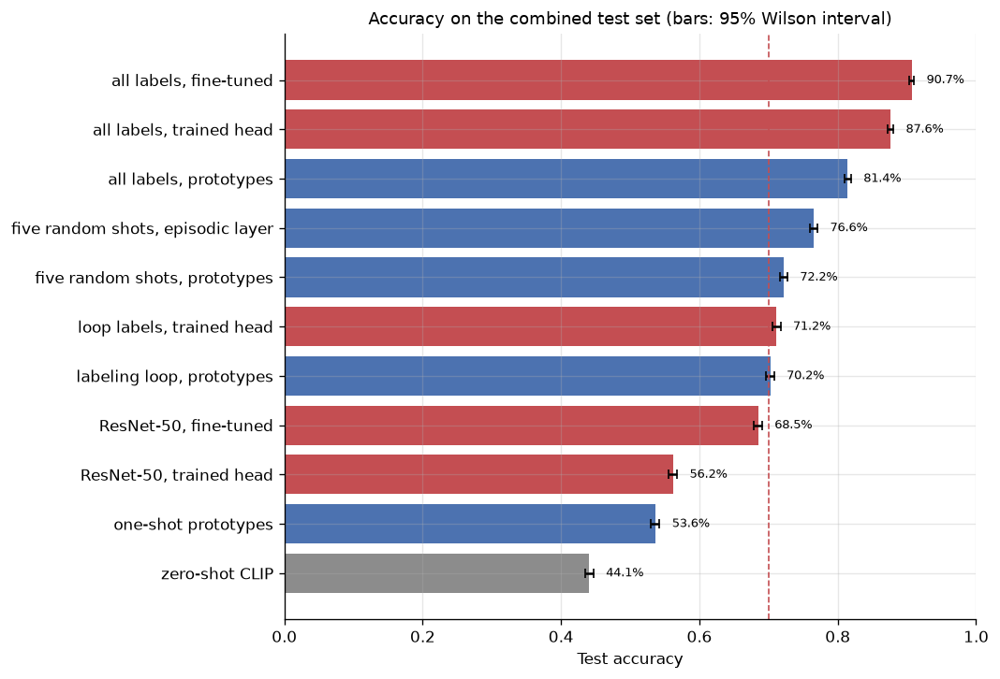

In [46]:
fig = plot_model_comparison(summary)
save_figure(fig, "model_comparison", "evaluation")
plt.show()

**The fine-tuned network is the best classifier, at 90.7% test accuracy (95% interval 90.3% to 91.0%):** the trained head reaches 87.6%, prototypes from every label 81.4%, the few-shot classifiers between 53.6% (one shot) and 76.6% (five random shots through the episodic layer of section 7), and zero-shot CLIP 44.1%. The labeling loop meets the brief's target at 70.2% with 6,702 labels, while five random labels per class (2,774) score 72.2% as plain prototypes and 76.6% once the episodic layer reweights the embedding. ResNet-50 stays far behind at every stage: 56.2% with a trained head and 68.5% fine-tuned on all labels, below the loop's few-shot classifier on DINOv2.

Every classifier finds the correct class in its top five far more often than in first place (the fine-tuned network 98.7%, the loop's prototypes 87.8%), and species-level accuracy adds only 1.6 points to the fine-tuned network (92.3%), so most of its mistakes name the wrong species, not the wrong plumage of the right one.

### Are the differences real?

McNemar's test looks only at the photographs two classifiers disagree on. If both had the same accuracy, each disagreement would be equally likely to favor either one.

In [47]:
correct = {name: scores.argmax(axis=1) == test_labels for name, (scores, _, _) in models.items()}
comparisons = [
    ("all labels, prototypes", "all labels, trained head"),
    ("all labels, trained head", "all labels, fine-tuned"),
    ("labeling loop, prototypes", "all labels, fine-tuned"),
    ("five random shots, prototypes", "five random shots, episodic layer"),
    ("ResNet-50, fine-tuned", "all labels, fine-tuned"),
]
display(
    pd.DataFrame(
        {f"{a} -> {b}": paired_comparison(correct[a], correct[b]) for a, b in comparisons}
    ).T.round(4)
)

,only_a_correct,only_b_correct,accuracy_difference,relative_error_reduction,statistic,p_value
"all labels, prototypes -> all labels, trained head",783.0,2298.0,0.0620,0.3338,743.9779,0.0
"all labels, trained head -> all labels, fine-tuned",399.0,1143.0,0.0304,0.2460,358.0084,0.0
"labeling loop, prototypes -> all labels, fine-tuned",539.0,5538.0,0.2044,0.6868,4110.5815,0.0
"five random shots, prototypes -> five random shots, episodic layer",1012.0,2084.0,0.0438,0.1575,370.4913,0.0
"ResNet-50, fine-tuned -> all labels, fine-tuned",386.0,5813.0,0.2219,0.7042,4749.3912,0.0


**Every step up is beyond chance:** learning a head instead of averaging prototypes fixes 2,298 test photographs and breaks 783 (6.2 points, a third of the prototypes' errors removed), fine-tuning the backbone fixes 1,143 and breaks 399 over the head (3.0 points, a quarter of its errors), and the fine-tuned network fixes 5,538 photographs the loop's few-shot classifier got wrong while breaking 539 (20.4 points, more than two thirds of its errors). The episodic layer's gain over plain five-shot prototypes holds on test (2,084 fixed against 1,012 broken, 4.4 points), and fine-tuned DINOv2 beats fine-tuned ResNet-50 on 5,813 photographs against 386. Every p-value rounds to zero at four decimals, so none of these differences comes from which photographs landed in the test set.

### How much of the result is the seed?

McNemar's test above asks whether a difference could come from which photographs landed in the test set. A second source of noise is training itself: the same recipe with another seed shuffles, crops and drops out differently and ends somewhere else. The fine-tuning runs of section 9 measure it.

,run,validation_accuracy,test_accuracy
0,recipe_seed42,0.9307,0.9002
1,recipe_seed43,0.9282,0.9036
2,recipe_seed44,0.9249,0.9028
3,epochs_8,0.9345,0.9068
4,blocks_12,0.9191,0.8952
5,lr_1e-05,0.9216,0.8944
6,lr_0.0001,0.9303,0.9046


recipe over three seeds: test 0.9022 (from 0.9002 to 0.9036)


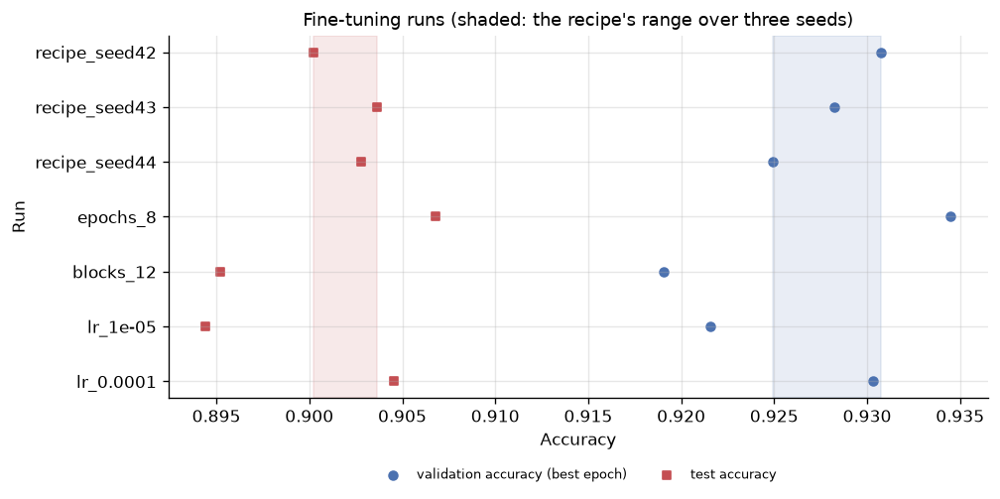

In [48]:
for name, setting in settings.items():
    model = fine_tune(
        train_files,
        val_files,
        head,
        config.FEWSHOT_BACKBONE,
        len(classes),
        log_dir=finetune_dir,
        name=name,
        **setting,
    )[0]
    probabilities = cached_predictions(
        model, test_files, eval_transform(mean, std), probability_dir / f"{name}_test.npy"
    )
    runs.loc[runs["run"] == name, "test_accuracy"] = (
        probabilities.argmax(axis=1) == test_labels
    ).mean()
display(runs[["run", "validation_accuracy", "test_accuracy"]].round(4))
recipe_runs = runs[runs["group"] == "recipe"]
print(
    f"recipe over three seeds: test {recipe_runs['test_accuracy'].mean():.4f} "
    f"(from {recipe_runs['test_accuracy'].min():.4f} to {recipe_runs['test_accuracy'].max():.4f})"
)
fig = plot_runs(runs)
save_figure(fig, "finetune_runs", "evaluation")
plt.show()

**The seed moves the recipe by a third of a point, and the longer schedule's gain holds on test:** the recipe's three seeds score 90.02%, 90.36% and 90.28% on test (mean 90.22%), a range of 0.34 points, about the half-width of one test score's own 95% interval (90.31% to 91.03% for the final network). Eight epochs score 90.68%, 0.32 points above the best seed and 0.46 above the mean, so the variant validation chose is also the best on test. It ran with one seed, though, and its margin is about one seed range, so the gain is real in direction and small in size.

The other runs keep their validation order too. The 1e-4 run, which tied the recipe on validation, lands at 90.46%, just above the recipe's test range, while twelve blocks (89.52%) and 1e-5 (89.44%) fall below every seed, as they did on validation. Validation ranks the runs correctly, which is what it was used for; its level runs about three points high, as the next subsection explains.

### Why validation scored higher than test

The trained models score about three points lower on test than on validation (the fine-tuned network 93.45% against 90.68%). A drop larger than the seed-to-seed spread measured above needs an explanation before the test number is trusted, and three explanations predict different evidence:

- **Closeness:** validation photographs might sit closer to some training photograph (the same photographer, outing or burst, short of the copies section 4 removed). Then reweighting test to validation's closeness closes the gap.
- **Class mix:** validation holds each class in proportion to its training count, test in its own proportions. Then reweighting test to validation's class mix closes the gap.
- **The split itself:** validation is a random tenth of NABirds' training split, while the test split was assembled separately by the dataset's authors. Then a model that never saw a training photograph shows no gap, while the models built from training photographs do.

In [49]:
val_probabilities = cached_predictions(
    finetuned,
    val["filename"].to_numpy(),
    eval_transform(mean, std),
    probability_dir / f"{final_run}_validation.npy",
)
resnet_val_probabilities = cached_predictions(
    resnet_finetuned,
    val["filename"].to_numpy(),
    eval_transform(resnet_mean, resnet_std),
    probability_dir / f"resnet50_lr_{resnet_lr:g}_validation.npy",
)
validation_scores = {
    "zero-shot CLIP": zero_shot_scores(features["clip_vit_b16"][validation_rows], text_features),
    "one-shot prototypes": first.scores(dino[validation_rows]),
    "five random shots, prototypes": five_shot.scores(dino[validation_rows]),
    "five random shots, episodic layer": five_shot_layer.scores(
        project(few_layer, dino[validation_rows])
    ),
    "labeling loop, prototypes": loop.model.scores(dino[validation_rows]),
    "all labels, prototypes": everyone.scores(dino[validation_rows]),
    "loop labels, trained head": head_scores(loop_head, dino[validation_rows]),
    "ResNet-50, trained head": head_scores(resnet_head, resnet[validation_rows]),
    "ResNet-50, fine-tuned": resnet_val_probabilities,
    "all labels, trained head": head_scores(head, dino[validation_rows]),
    "all labels, fine-tuned": val_probabilities,
}
gaps = pd.DataFrame(
    {
        "validation": {
            name: (scores.argmax(axis=1) == labels[validation_rows]).mean()
            for name, scores in validation_scores.items()
        },
        "test": summary.set_index("model")["accuracy"],
    }
)
display(gaps.assign(gap=gaps["validation"] - gaps["test"]).round(4))

,validation,test,gap
zero-shot CLIP,0.4414,0.4407,0.0007
one-shot prototypes,0.5403,0.5362,0.0040
"five random shots, prototypes",0.7505,0.7217,0.0288
"five random shots, episodic layer",0.7914,0.7656,0.0258
"labeling loop, prototypes",0.7113,0.7024,0.0090
"all labels, prototypes",0.8315,0.8144,0.0171
"loop labels, trained head",0.7326,0.7116,0.0209
"ResNet-50, trained head",0.6337,0.5617,0.0720
"ResNet-50, fine-tuned",0.7451,0.6848,0.0602
"all labels, trained head",0.9086,0.8763,0.0323


In [50]:
closeness = {
    name: nearest_reference_similarity(dino[rows], dino[pool])
    for name, rows in (("validation", validation_rows), ("test", test_rows))
}
hits = {
    "validation": val_probabilities.argmax(axis=1) == labels[validation_rows],
    "test": correct["all labels, fine-tuned"],
}
display(
    pd.DataFrame(
        {name: pd.Series(values).describe() for name, values in closeness.items()}
    ).T.round(3)
)
display(accuracy_by_closeness(closeness, hits).round(3))
by_closeness = reweighted_accuracy(closeness["validation"], closeness["test"], hits["test"])
by_class_mix = class_mix_accuracy(hits["test"], test_labels, labels[validation_rows])
print(
    f"fine-tuned test accuracy {hits['test'].mean():.4f}; "
    f"reweighted to validation's closeness {by_closeness:.4f}; "
    f"to validation's class mix {by_class_mix:.4f}"
)

,count,mean,std,min,25%,50%,75%,max
validation,2397.0,0.810,0.087,0.326,0.766,0.827,0.871,0.959
test,24455.0,0.804,0.085,0.158,0.761,0.820,0.864,0.959


,band,validation_photographs,validation_accuracy,validation_share,test_photographs,test_accuracy,test_share
0,"[0.0, 0.7)",254,0.811,0.106,2713,0.787,0.111
1,"[0.7, 0.8)",633,0.912,0.264,7043,0.899,0.288
2,"[0.8, 0.85)",631,0.959,0.263,6618,0.924,0.271
3,"[0.85, 0.9)",627,0.965,0.262,6080,0.938,0.249
4,"[0.9, 0.95)",245,0.980,0.102,1971,0.948,0.081
5,"[0.95, 1.0)",7,1.000,0.003,30,1.000,0.001


fine-tuned test accuracy 0.9068; reweighted to validation's closeness 0.9089; to validation's class mix 0.9103


**The gap belongs to the split, not to closeness or class mix:** zero-shot CLIP, which never saw a training photograph, scores 44.14% on validation and 44.07% on test, while every model built from training photographs loses between 0.4 points (one shot) and 7.2 points (the ResNet-50 head). The other two explanations fail their tests. Validation and test photographs sit equally close to the training data (median nearest similarity 0.827 against 0.820), test scores lower than validation in every closeness band with more than a handful of photographs, and reweighting test to validation's closeness or class mix moves the fine-tuned network's 90.68% only to 90.89% and 91.03%.

The drop also follows the features: the two ResNet-50 models lose 7.2 and 6.0 points, against 3.2 and 2.8 for the DINOv2 head and fine-tuned network. That is consistent with a difference in the photographs themselves, which features learned from ImageNet's labels carry over to new photographs less well than DINOv2's. Validation is a random draw from the split the models were trained on, while NABirds' authors assembled the test split separately, in a way a random draw does not reproduce; the Activeloop copy keeps no photographer or date to test which. The consequence is practical: validation was a fair judge of every relative choice above, since all candidates were measured the same way, and the seed runs show it ranked them correctly, but its absolute numbers run about three points high, and the test numbers are the ones to quote.

### What each approach costs at prediction time

In [51]:
backbone = Backbone(config.FEWSHOT_BACKBONE)
timing = pd.DataFrame(
    {
        "few-shot: embedding + prototypes": time_per_image(
            image_predictor(backbone, backbone.transform, loop.model.scores), test_files
        ),
        "fine-tuned DINOv2": time_per_image(
            image_predictor(finetuned, eval_transform(mean, std)), test_files
        ),
        "fine-tuned ResNet-50": time_per_image(
            image_predictor(resnet_finetuned, eval_transform(resnet_mean, resnet_std)), test_files
        ),
    }
).T
display(timing.round(1))

,images,median_ms,p95_ms
few-shot: embedding + prototypes,100.0,29.0,31.7
fine-tuned DINOv2,100.0,28.2,29.7
fine-tuned ResNet-50,100.0,17.2,19.3


**Both DINOv2 approaches cost the same at prediction time, a median under 30 milliseconds per photograph:** the few-shot classifier takes a median of 29.0 ms (95th percentile 31.7 ms) and the fine-tuned network 28.2 ms (29.7 ms), from the file on disk to class scores on the laptop's GPU. Both run the same backbone once per photograph, and comparing an embedding with 555 prototypes costs about as little as a linear head. ResNet-50 is faster (17.2 ms) and 22 points less accurate. The approaches differ in what they cost before deployment, labels and training time, not in speed.

### Where the two approaches differ

,"labeling loop, prototypes","all labels, fine-tuned"
correct,17176,22175
wrong species,6516,1895
"wrong variant, right species",763,385


,size_quartile,bird_share_of_frame,"labeling loop, prototypes","all labels, fine-tuned"
0,Q1,0% to 17%,0.674,0.867
1,Q2,17% to 28%,0.723,0.921
2,Q3,28% to 41%,0.721,0.926
3,Q4,42% to 100%,0.692,0.913


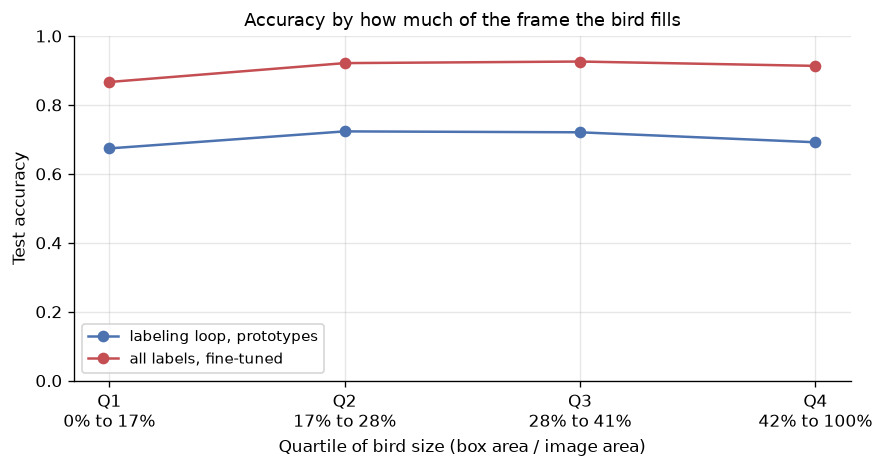

In [52]:
compared = ("labeling loop, prototypes", "all labels, fine-tuned")
display(
    pd.DataFrame(
        {
            name: error_kinds(test_labels, models[name][0].argmax(axis=1), species)
            for name in compared
        }
    )
)
size_table = accuracy_by_size(
    test["box_fraction"].to_numpy(), {name: correct[name] for name in compared}
)
display(size_table.round(3))
fig = plot_accuracy_by_size(
    size_table,
    dict(zip(compared, (config.PALETTE["fewshot"], config.PALETTE["finetuned"]), strict=True)),
)
save_figure(fig, "accuracy_by_size", "evaluation")
plt.show()

**Fine-tuning removes mostly species errors, and its lead holds at every bird size:** the few-shot classifier gets 6,516 test photographs wrong at the species level and 763 only in the plumage; the fine-tuned network cuts those to 1,895 and 385. Both are weakest when the bird fills under 17% of the frame (67.4% and 86.7%), where field marks shrink to a few pixels after resizing, and the fine-tuned network leads by 19.3 to 22.1 points in every quartile, so its advantage is not confined to easy, frame-filling birds. Both also dip slightly for the largest birds (69.2% and 91.3%), probably because that is the quartile where the center crop most often trims part of the bird (section 6).

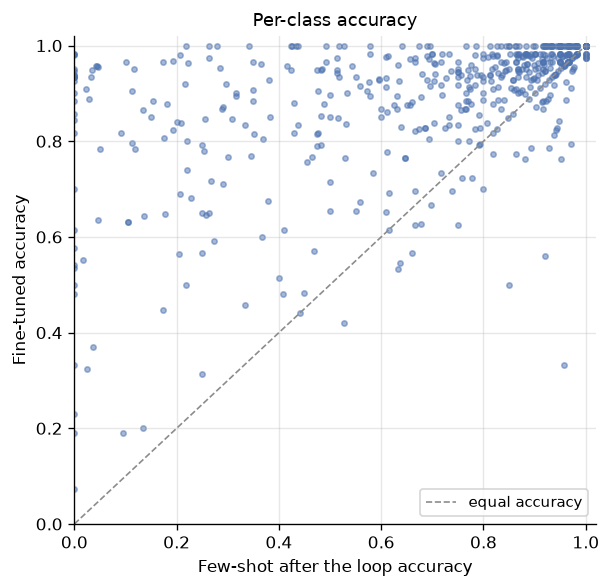

fine-tuned per-class accuracy against training photographs per class: Spearman 0.42


In [53]:
class_accuracy = {
    name: per_class_accuracy(test_labels, models[name][0].argmax(axis=1), len(classes))
    for name in compared
}
fig = plot_per_class(
    class_accuracy[compared[0]],
    class_accuracy[compared[1]],
    "Few-shot after the loop",
    "Fine-tuned",
)
save_figure(fig, "per_class", "evaluation")
plt.show()
spearman = pd.Series(class_accuracy[compared[1]]).corr(pd.Series(train_counts), method="spearman")
print(
    f"fine-tuned per-class accuracy against training photographs per class: Spearman {spearman:.2f}"
)

**The fine-tuned network is better on almost every class:** nearly all dots sit above the diagonal, and many classes the few-shot classifier almost never got right reach 80% or more after fine-tuning; only a handful fall below the line, where the two models trade errors within a look-alike pair. Per-class accuracy correlates only moderately with the number of training photographs (Spearman 0.42), so a class's sample size explains part of its accuracy and its neighbors explain much of the rest, as the confusions below show.

In [54]:
confusions = confused_pairs(
    test_labels, finetuned_probabilities.argmax(axis=1), classes["class_name"].to_numpy(), species
)
display(confusions[["true_class", "predicted_class", "errors", "same_species"]])

,true_class,predicted_class,errors,same_species
0,Black-capped Chickadee,Carolina Chickadee,24,False
1,Red-naped Sapsucker,Yellow-bellied Sapsucker,21,False
2,Western Screech-Owl,Eastern Screech-Owl,18,False
3,Greater Scaup (Female/Eclipse male),Lesser Scaup (Female/Eclipse male),18,False
4,"Allen's Hummingbird (Female, immature)","Rufous Hummingbird (Female, immature)",18,False
5,Greater Scaup (Breeding male),Lesser Scaup (Breeding male),17,False
6,Pacific Wren,Winter Wren,17,False
7,Yellow-rumped Warbler (Breeding Audubon's),Yellow-rumped Warbler (Winter/juvenile Audubon's),17,True
8,Pacific-slope Flycatcher,Cordilleran Flycatcher,16,False
9,Chihuahuan Raven,Common Raven,14,False


**The remaining errors are the identifications birders argue about:** the most frequent mistake calls a Black-capped Chickadee a Carolina Chickadee (24 times), followed by Red-naped against Yellow-bellied Sapsucker (21), Western against Eastern Screech-Owl (18), the female and eclipse plumages of Greater and Lesser Scaup (18), the females and immatures of Allen's and Rufous Hummingbird (18) and the breeding males of the two scaups (17), pairs that experienced birders separate by a single field mark, by range or by voice. Only one of the ten pairs confuses two plumages of one species (breeding and winter Audubon's Yellow-rumped Warbler, 17). Three of the pairs (the chickadees, the breeding-male scaups and the screech-owls) are among the four closest prototypes of section 7, so the embedding's geometry predicted where even the trained network would struggle.

### How far the confidence can be trusted

The most confident mistakes in section 11 carry 97% or 98% confidence, and LIME's examples are chosen by confidence, so it matters whether the model's probabilities mean what they say. Calibration compares stated confidence with observed accuracy: of all predictions made with about 80% confidence, about 80% should be right. The expected calibration error (ECE; Guo et al. 2017) sorts the predictions into fifteen equal-width bins of confidence, takes the gap between average confidence and accuracy within each bin, and averages the gaps weighted by each bin's share of the photographs. The reliability diagram draws the same bins. Temperature scaling, the standard repair from the same paper, divides every logit by one number T fitted on validation: it never changes which class wins, only how sure the model says it is.

,accuracy,mean confidence,ECE,negative log-likelihood
trained head,0.8763,0.7458,0.1306,0.5955
fine-tuned,0.9068,0.7444,0.1623,0.5335
"fine-tuned, temperature 0.61",0.9068,0.9306,0.0253,0.3553


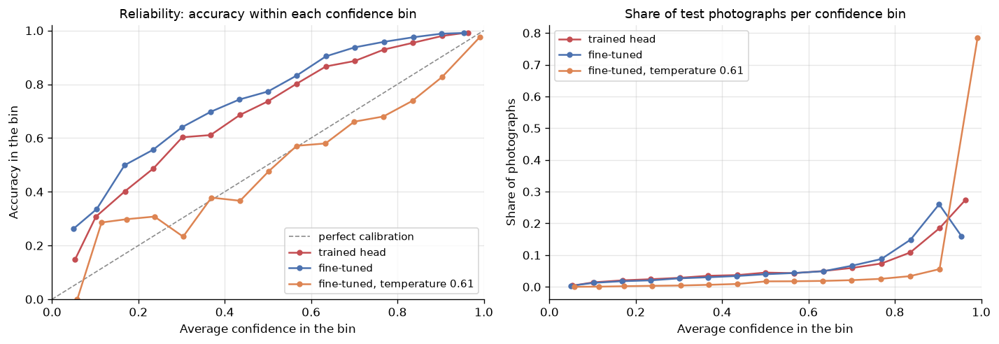

In [55]:
temperature = fit_temperature(val_probabilities, labels[validation_rows])
confidence_sets = {
    "trained head": head_scores(head, dino[test_rows]),
    "fine-tuned": finetuned_probabilities,
    f"fine-tuned, temperature {temperature:.2f}": apply_temperature(
        finetuned_probabilities, temperature
    ),
}
calibration = pd.DataFrame(
    {
        name: {
            "accuracy": (scores.argmax(axis=1) == test_labels).mean(),
            "mean confidence": scores.max(axis=1).mean(),
            "ECE": calibration_error(scores, test_labels),
            "negative log-likelihood": negative_log_likelihood(scores, test_labels),
        }
        for name, scores in confidence_sets.items()
    }
).T
display(calibration.round(4))
fig = plot_reliability(
    {name: reliability_table(scores, test_labels) for name, scores in confidence_sets.items()}
)
save_figure(fig, "reliability", "evaluation")
plt.show()

In [56]:
confidence = finetuned_probabilities.max(axis=1)
mistake = finetuned_probabilities.argmax(axis=1) != test_labels
scaled_confidence = confidence_sets[f"fine-tuned, temperature {temperature:.2f}"].max(axis=1)
right_median, wrong_median = np.median(confidence[~mistake]), np.median(confidence[mistake])
print(
    f"median confidence: right {right_median:.1%}, wrong {wrong_median:.1%}; "
    f"mistakes at 90% confidence or more: {(confidence[mistake] >= 0.9).sum()} "
    f"of {mistake.sum():,} "
    f"({(scaled_confidence[mistake] >= 0.9).sum()} after temperature scaling)"
)
confident_after = scaled_confidence >= 0.9
print(
    f"after scaling, {confident_after.sum():,} test photographs carry 90% confidence or more, "
    f"and {(~mistake[confident_after]).mean():.1%} of them are right"
)
display(reliability_table(finetuned_probabilities, test_labels).round(3))

median confidence: right 85.3%, wrong 39.4%; mistakes at 90% confidence or more: 69 of 2,280 (573 after temperature scaling)
after scaling, 19,998 test photographs carry 90% confidence or more, and 97.1% of them are right


,bin,range,photographs,confidence,accuracy,share
0,0,0.00 to 0.07,80,0.050,0.262,0.003
1,1,0.07 to 0.13,310,0.103,0.335,0.013
2,2,0.13 to 0.20,433,0.168,0.499,0.018
3,3,0.20 to 0.27,498,0.234,0.556,0.020
4,4,0.27 to 0.33,653,0.301,0.640,0.027
5,5,0.33 to 0.40,738,0.368,0.698,0.030
6,6,0.40 to 0.47,834,0.434,0.743,0.034
7,7,0.47 to 0.53,970,0.500,0.773,0.040
8,8,0.53 to 0.60,1066,0.567,0.833,0.044
9,9,0.60 to 0.67,1201,0.635,0.904,0.049


**The fine-tuned network is underconfident, not overconfident:** its average confidence on test is 74.4% while it is right 90.7% of the time, and accuracy runs above confidence in every bin; predictions made with about 50% confidence, for example, are right 77.3% of the time. The expected calibration error is 16.2%, and the trained head shows the same pattern (13.1%). Label smoothing explains the direction: both were trained to put about 90% of the probability on the right class and spread the rest over the other 554, so their probabilities sit below the true chances, and further below on new photographs. Temperature scaling with T = 0.61, fitted on validation, sharpens them: the test ECE falls to 2.5% and the negative log-likelihood from 0.534 to 0.355, with accuracy unchanged by construction.

The 97% and 98% confident mistakes that LIME examines are a thin tail: the median confidence is 85.3% for right predictions and 39.4% for wrong ones, and only 69 of the 2,280 mistakes reach 90% confidence. Calibration cannot remove that tail, and sharpening even moves 573 mistakes above 90%, since the calibrated model is that confident about most of the test set: 19,998 photographs, of which 97.1% are right. That is the property a reject option needs. With calibrated probabilities, a threshold such as 90% means what it says, and the photographs below it can go to a birder or get the species or the look-alike pair as the answer. The confident mistakes themselves remain the look-alike pairs of the confusion table above.

## 11. Explaining the fine-tuned model with LIME

LIME (local interpretable model-agnostic explanations) explains one prediction at a time. It cuts the model's input into superpixels (here with quickshift), makes 1,000 copies with random subsets of superpixels blacked out, records the model's probability for the explained class on each copy, and fits a linear model that predicts that probability from which superpixels were present, weighting each copy by how close it is to the original. The superpixels with the largest positive weights are the regions the prediction leaned on; the five strongest are outlined in yellow below.

The bounding boxes were never shown to any model, so they can grade the explanations: if the evidence sits on the bird, most of its area falls inside the green box. A large bird leaves little room outside its box, so the share inside is read against the box's own share of the input. Their ratio, the lift, is 1 for evidence scattered at random and grows as the evidence concentrates on the bird. The best predictions are the most confident correct ones and the worst are the most confident wrong ones, because a confident mistake says more about what the model learned than an uncertain one.

In [57]:
best, worst = best_and_worst(finetuned_probabilities, test_labels, config.LIME_METRIC_EXAMPLES)
chosen = test.iloc[np.concatenate([best, worst])]
predicted = finetuned_probabilities[np.concatenate([best, worst])].argmax(axis=1)
corners = [
    box_in_crop((row.box_x, row.box_y, row.box_w, row.box_h), row.width, row.height)
    for row in chosen.itertuples()
]
predict = probability_function(finetuned, mean, std)
lime_dir = config.INTERIM_DIR / "lime"
lime_table, masks = explain_many(
    chosen["filename"].tolist(),
    predicted,
    corners,
    predict,
    lime_dir / "best_and_worst.npz",
    finetuned.cache_key,
)
lime_table["group"] = ["best"] * len(best) + ["worst"] * len(worst)

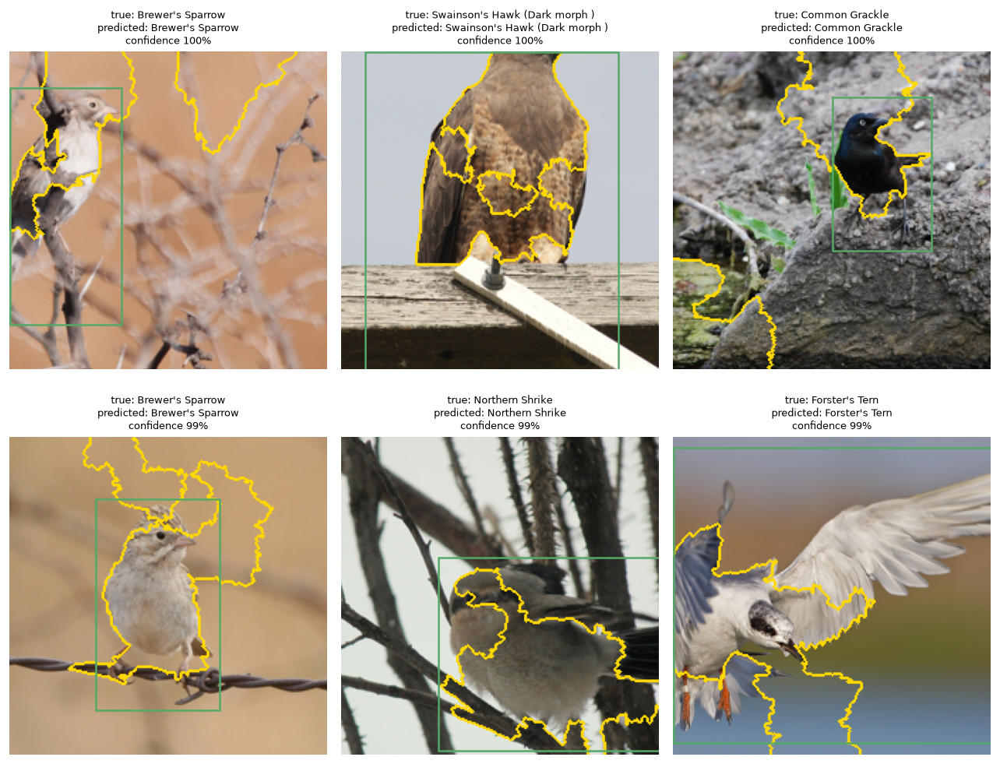

In [58]:
names = classes["class_name"].to_numpy()
confidence = finetuned_probabilities[np.concatenate([best, worst])].max(axis=1)
titles = [
    f"true: {names[t]}\npredicted: {names[p]}\nconfidence {c:.0%}"
    for t, p, c in zip(chosen["class_index"], predicted, confidence, strict=True)
]
shown = config.LIME_EXAMPLES
fig = lime_grid(
    [model_input(name) for name in chosen["filename"].iloc[:shown]],
    masks[:shown],
    corners[:shown],
    titles[:shown],
    columns=config.LIME_COLUMNS,
)
save_figure(fig, "lime_best", "explain")
plt.show()

**On the most confident correct predictions, the evidence mostly sits on the bird:** the dark-morph Swainson's Hawk, the Northern Shrike and the Forster's Tern are explained by superpixels on the bird itself, the tern's black cap and wing among them. The Common Grackle and the two Brewer's Sparrows also draw on their surroundings (rocks, a wire, out-of-focus branches), the kind of background where each species is usually photographed. A confident, correct prediction does not prove the model looked only at the bird.

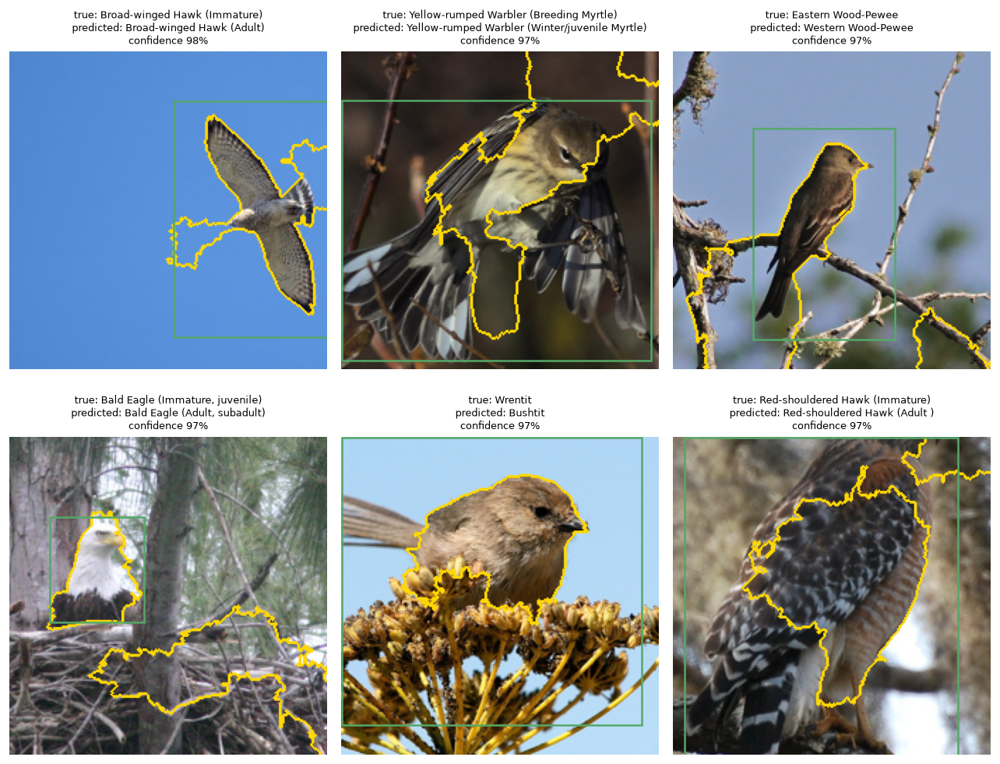

In [59]:
offset = len(best)
worst_slice = slice(offset, offset + shown)
fig = lime_grid(
    [model_input(name) for name in chosen["filename"].iloc[worst_slice]],
    masks[worst_slice],
    corners[worst_slice],
    titles[worst_slice],
    columns=config.LIME_COLUMNS,
)
save_figure(fig, "lime_worst", "explain")
plt.show()

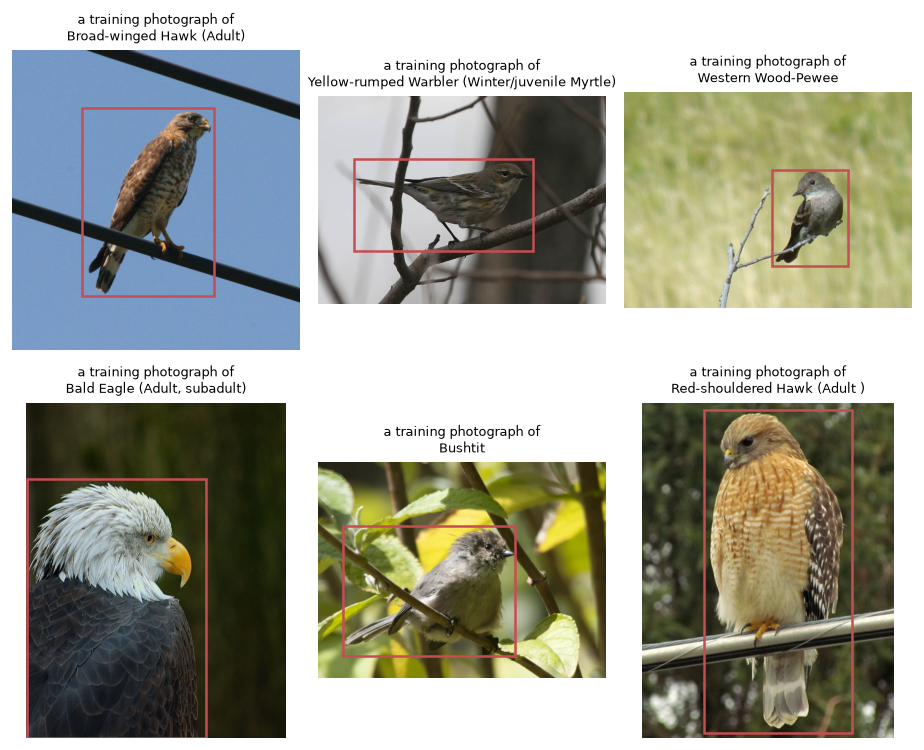

In [60]:
reference_rows = pd.concat(
    [train[train["class_index"] == label].head(1) for label in predicted[worst_slice]]
)
fig = image_grid(
    photo_panels(
        reference_rows,
        [f"a training photograph of\n{names[label]}" for label in predicted[worst_slice]],
    ),
    columns=config.LIME_COLUMNS,
)
save_figure(fig, "worst_references", "explain")
plt.show()

**The most confident mistakes are mistakes a birder could make, and two may not be mistakes at all:** an immature Broad-winged Hawk called an adult, a breeding Myrtle Yellow-rumped Warbler called the winter plumage of the same form, an Eastern Wood-Pewee called a Western Wood-Pewee, a Wrentit called a Bushtit, and an immature Bald Eagle and an immature Red-shouldered Hawk both called adults. The two wood-pewees are told apart mainly by voice and range, and the warbler, in a dull plumage, sits on a boundary between two classes that molt blurs. The eagle in the photograph has the white head and yellow bill of an adult, and the Red-shouldered Hawk shows an adult's rufous-barred breast, so these two look like errors in the labels rather than in the model. In most of the six the evidence lies on the bird, with the eagle's nest, the Wrentit's flower head and the pewee's branches also carrying weight. The training photographs of each predicted class, in the row of references, show how close the confusions are.

In [61]:
display(
    lime_table.groupby("group")[["evidence_inside_box", "box_share_of_input", "lift"]]
    .median()
    .round(3)
)

,evidence_inside_box,box_share_of_input,lift
group,,,
best,0.918,0.459,1.863
worst,0.863,0.451,1.642


**Measured over twenty photographs per group, the evidence concentrates on the bird for the best and the worst predictions alike:** the median share of LIME's evidence inside the box is 91.8% for the best predictions and 86.3% for the worst, while the box covers a median 45.9% and 45.1% of the input, the share evidence scattered at random would reach. The median lift is 1.86 and 1.64, so the evidence lands on the bird at almost twice the rate chance allows. The worst predictions lean on their surroundings a little more, and a few of them have a lift close to 1, but the confident mistakes come mostly from looking at the bird and misreading it, not from a background shortcut such as a watermark or a habitat. These photographs are mostly birds that fill half the input, though, which leaves little room outside the box, so the next subsection separates small and large birds.

### Small birds and large birds

The best and worst predictions above are mostly birds that fill the frame. A second sample checks size directly: twenty random test photographs from the smallest quartile of bird size and twenty from the largest, each explained for its predicted class in the same way, right or wrong.

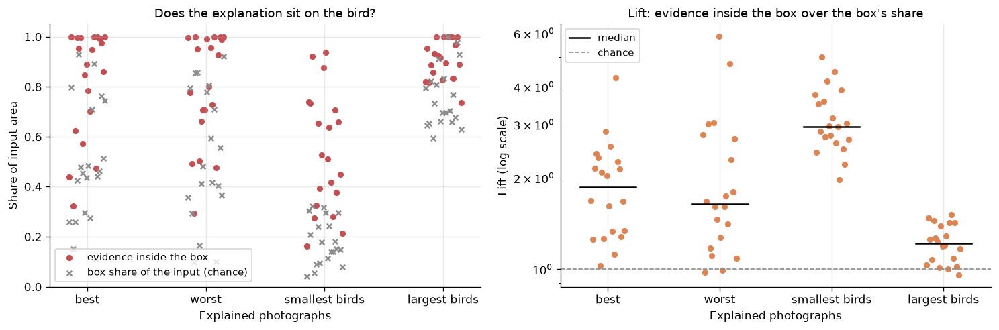

,evidence_inside_box,box_share_of_input,lift,correct
group,,,,
best,0.918,0.459,1.863,NaN
worst,0.863,0.451,1.642,NaN
smallest birds,0.520,0.165,2.958,0.9
largest birds,0.921,0.719,1.219,0.9


In [62]:
quartile = pd.qcut(test["box_fraction"], config.SIZE_BINS, labels=False).to_numpy()
sampler = np.random.default_rng(config.RANDOM_SEED)
size_rows = np.concatenate(
    [
        sampler.choice(np.flatnonzero(quartile == q), config.LIME_SIZE_EXAMPLES, replace=False)
        for q in (0, config.SIZE_BINS - 1)
    ]
)
sized = test.iloc[size_rows]
size_predicted = finetuned_probabilities[size_rows].argmax(axis=1)
size_corners = [
    box_in_crop((row.box_x, row.box_y, row.box_w, row.box_h), row.width, row.height)
    for row in sized.itertuples()
]
size_table, size_masks = explain_many(
    sized["filename"].tolist(),
    size_predicted,
    size_corners,
    predict,
    lime_dir / "by_size.npz",
    finetuned.cache_key,
)
size_table["group"] = ["smallest birds"] * config.LIME_SIZE_EXAMPLES + [
    "largest birds"
] * config.LIME_SIZE_EXAMPLES
size_table["correct"] = size_predicted == sized["class_index"].to_numpy()
lime_scores = pd.concat([lime_table, size_table], ignore_index=True)
fig = plot_lime_overlap(lime_scores)
save_figure(fig, "lime_overlap", "explain")
plt.show()
display(
    lime_scores.groupby("group", sort=False)[["evidence_inside_box", "box_share_of_input", "lift"]]
    .median()
    .assign(correct=size_table.groupby("group", sort=False)["correct"].mean())
    .round(3)
)

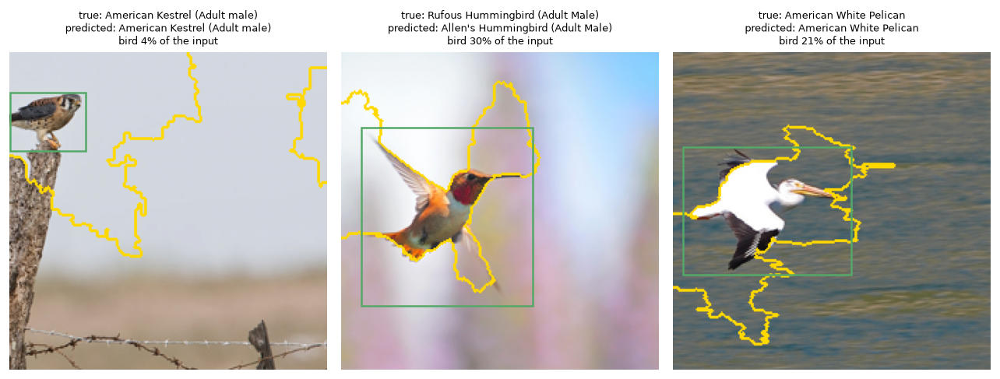

In [63]:
small_shown = slice(0, config.LIME_COLUMNS)
size_titles = [
    f"true: {names[t]}\npredicted: {names[p]}\nbird {share:.0%} of the input"
    for t, p, share in zip(
        sized["class_index"], size_predicted, size_table["box_share_of_input"], strict=True
    )
]
fig = lime_grid(
    [model_input(name) for name in sized["filename"].iloc[small_shown]],
    size_masks[small_shown],
    size_corners[small_shown],
    size_titles[small_shown],
    columns=config.LIME_COLUMNS,
)
save_figure(fig, "lime_small_birds", "explain")
plt.show()

**For small birds, half of the evidence falls outside the box, even though relative to chance it is the most concentrated:** over twenty random photographs of the smallest birds, whose box covers a median 16.5% of the input, 52.0% of the evidence lies inside the box, against 92.1% for the twenty largest birds, whose box covers 71.9%. The 92% medians of the best and worst predictions therefore describe large birds; on small birds the evidence includes far more of the scene. Read against chance, the picture reverses: the lift is 2.96 for small birds and 1.22 for large ones, because a large box leaves little area for the evidence to miss.

Part of the outside share is the method rather than the model. LIME marks whole superpixels, and the five strongest ones around a small bird reach well past its box, as the pelican shows. Part of it is the model: the kestrel's evidence lies in the sky and on the post around it, not on the bird, so on some small birds the network does use the scene. In this sample both groups are classified equally well (18 of 20 right in each), so the extra background evidence costs nothing measurable here, while section 10's size quartiles show that small birds are where the network is weakest overall.

### Are the explanations stable?

LIME's evidence depends on which random copies it draws. The six best and six worst photographs shown above are explained again with two other sampling seeds, with the segmentation kept fixed, so only the random copies change. Two evidence masks are compared by their intersection over union: 1 when they mark the same pixels, 0 when they share none.

In [64]:
rerun = list(range(config.LIME_EXAMPLES)) + list(range(len(best), len(best) + config.LIME_EXAMPLES))
stability = []
for seed in config.LIME_SEEDS:
    seed_table, seed_masks = explain_many(
        chosen["filename"].iloc[rerun].tolist(),
        predicted[rerun],
        [corners[i] for i in rerun],
        predict,
        lime_dir / f"seed_{seed}.npz",
        finetuned.cache_key,
        seed=seed,
    )
    stability.append(
        pd.DataFrame(
            {
                "group": lime_table["group"].iloc[rerun].to_numpy(),
                "seed": seed,
                "overlap_with_seed_42": [
                    mask_overlap(masks[i], seed_mask)
                    for i, seed_mask in zip(rerun, seed_masks, strict=True)
                ],
                "inside_box_change": (
                    seed_table["evidence_inside_box"].to_numpy()
                    - lime_table["evidence_inside_box"].iloc[rerun].to_numpy()
                ),
            }
        )
    )
stability = pd.concat(stability, ignore_index=True)
display(
    stability.groupby("group")[["overlap_with_seed_42", "inside_box_change"]]
    .agg(["median", "min", "max"])
    .round(3)
)

overlap_with_seed_42             inside_box_change              
                    median    min  max            median    min    max
group                                                                 
best                 0.879  0.592  1.0               0.0  0.000  0.132
worst                0.779  0.422  1.0               0.0 -0.071  0.141

**The explanations are stable enough to read, the worst predictions less so:** with the segmentation fixed, rerunning LIME with two other sampling seeds marks largely the same superpixels. The median overlap with seed 42's evidence is 0.879 for the best predictions and 0.779 for the worst, and the least stable explanations still overlap 0.592 and 0.422. The share of evidence inside the box does not move in the median and moves by 14 points at most in any photograph (from 7 points lower to 14 higher), so the conclusions above do not depend on LIME's sampling. The worst predictions are probably less stable because a confident mistake has no single decisive region: when several regions support the wrong class about equally, which of them make the top five changes with the random copies.

## 12. Conclusion, limitations and recommendations

### Conclusion

**Both approaches meet the brief, at very different costs:** a prototype classifier on frozen DINOv2 embeddings, started from one labeled photograph per class and grown by confirming its own most confident predictions, reaches 70.2% on the combined test set after three rounds and 6,702 labels. The same backbone with a trained head and its top four blocks fine-tuned for eight epochs on the fully labeled training set reaches 90.7% (95% interval 90.3% to 91.0%), and the four-epoch recipe averages 90.2% over three seeds. Both classify a photograph in under 30 ms, so the trade is between labels and accuracy, not speed.

**What decided the results:**

- **The backbone mattered most:** with the same five labels per class, DINOv2 prototypes reach 74.7% on validation against 52.8% for CLIP and 33.3% for ResNet-50, and ResNet-50 stays 22 points behind even when both networks are fine-tuned (68.5% against 90.7% on test).
- **What the labeler sees matters as much as how many labels it gives:** confirming the classifier's most confident predictions needed 6,702 labels to reach 70%, while five random labels per class (2,774) give 72.2% on test. When the labeler names the class instead of only confirming, asking about the most uncertain photographs reaches 83.9% on validation after eight rounds, against 78.4% for confident proposals and 72.2% for the brief's confirm-only loop.
- **Label quality matters as much as label count:** a labeler who slips 20% of the time, or confirms half of the look-alike proposals, leaves about a tenth of the labeled set wrong by round 12, and the loop stalls near 70% instead of climbing to 73.6%.
- **Training beats averaging on the same labels:** a linear head on all labels removes a third of the prototypes' test errors (87.6% against 81.4%), fine-tuning removes a further quarter (90.7%), and even with five labels per class, a small layer trained on practice episodes lifts the prototypes from 72.2% to 76.6% on test.
- **The data needed one real fix:** no file was corrupt, and 345 duplicates were removed with a similarity threshold chosen without test labels, including 28 training copies of test photographs.

### Limitations

- **The labelers are simulated:** the error-prone ones slip at fixed rates, at random or on look-alike pairs. A person's mistakes would vary with fatigue, photograph quality and the class, and the ambiguous cases the gallery shows, such as two birds of different classes in one photograph, are not modeled.
- **The loop's stopping rule reads the test set,** because the brief says so. Validation reached 70% in the same round, so the round did not depend on it, but the loop's 70.2% is not an untouched test score.
- **Validation runs optimistic,** by about three points for every DINOv2 model built from training photographs and six to seven for ResNet-50 (section 10). Relative choices made on it held up on test; its absolute numbers do not transfer to the test split.
- **The final network's margin is small and comes from one seed:** eight epochs beat the recipe's mean by 0.46 points on test, a little more than the recipe's seed range (0.34 points). ResNet-50's best learning rate is the top of its grid, and fine-tuning at 448 pixels was not run.
- **Some labels look wrong:** two of the six most confident mistakes show adult plumage under an immature label, so part of the measured error is label noise in NABirds' age classes.
- **LIME is an approximation:** it explains a local linear surrogate built from blacked-out superpixels, and its superpixels are coarse next to a small bird. Twenty photographs per group is a small sample, though the reruns with other seeds show that the conclusions do not depend on LIME's sampling.
- **The pretrained backbones may have seen these photographs:** DINOv2 and CLIP were trained on large web collections that could include NABirds images, which would flatter the few-shot and zero-shot numbers more than the fine-tuned one.

### Recommendations

- **Let the labeler name the class, show it the uncertain photographs, and audit the look-alike confirmations:** in this simulation that protocol reaches 83.9% on validation after eight rounds against 72.2% for the brief's rule, and wrong labels compound from round to round, so checking a sample of each round's confirmations, starting with look-alike pairs, protects the gain.
- **Train the few-shot embedding on the labels at hand:** the episodic layer trains in seconds on cached features and added 4.4 points on test with five labels per class.
- **Give small birds more pixels:** at 448 pixels the frozen features already lift five-shot prototypes on the smallest birds (72.3% to 75.6% on validation). Cropping the bird with a detector before classifying would give the fine-tuned network the same detail without four times the cost per step.
- **Use the calibrated probabilities to decide when to answer:** after temperature scaling, the 19,998 test photographs with 90% confidence or more are right 97.1% of the time. Below that threshold, answer with the species or the look-alike pair, or ask a birder.
- **Have an expert recheck the age classes,** starting with the most confident mistakes; where the label is wrong, the network is better than its score.
- **Hold validation out by photographer or date** if NABirds' original metadata is available, so that validation numbers predict test numbers.

In [65]:
tables = {
    "partitions": parts[["filename", "split", "partition", "class_index", "group"]],
    "removed_duplicates": resolved.loc[
        resolved["drop_reason"] != "", ["filename", "split", "class_index", "group", "drop_reason"]
    ],
    "backbone_curves": curves,
    "episodic_layer": episodic,
    "labeling_history": loop.history,
    "labeler_robustness": robustness,
    "query_strategies": strategies,
    "head_search": trials,
    "finetune_history": read_history(finetune_dir, final_run),
    "finetune_runs": runs,
    "test_results": summary,
    "calibration": calibration.reset_index(names="model"),
    "lime_scores": lime_scores,
    "lime_stability": stability,
}
print(write_processed(tables))

['backbone_curves.csv', 'calibration.csv', 'episodic_layer.csv', 'finetune_history.csv', 'finetune_runs.csv', 'head_search.csv', 'labeler_robustness.csv', 'labeling_history.csv', 'lime_scores.csv', 'lime_stability.csv', 'partitions.csv', 'query_strategies.csv', 'removed_duplicates.csv', 'test_results.csv']


Every file in `data/processed/` is written by the cell above, so none of them can drift from what this notebook shows.